# Fase 2 de CRISP-DM: comprensión de los datos

**Proyecto:** Trayectorias de participación electoral en México: segmentación de secciones electorales 2009–2024

Este notebook hace **toda la fase 2 desde cero**, a la vista:
1. Descarga las fuentes oficiales si no están en `data/raw/`.
2. Lee los 192 archivos crudos de los Conteos Censales y verifica cada uno.
3. Calcula cada tabla y dibuja cada gráfica, con una explicación de **cómo leerla** y **qué nos dice**.

Acompaña al reporte [`docs/fase2_comprension_datos.md`](../docs/fase2_comprension_datos.md). Los scripts de `src/fase2/` hacen los mismos cálculos en modo «producción» (guardan tablas y figuras en `resultados/fase2/`); este notebook los presenta paso a paso para leerlos.

**Cómo correrlo.** Desde la raíz del repositorio:

```
uv run --with jupyter --with pandas --with pyarrow --with openpyxl --with matplotlib --with jinja2 \
       --with geopandas --with scikit-learn --with requests jupyter lab notebooks/
```

La primera vez descarga ~0.46 GB. La ejecución completa tarda unos 15 minutos: leer los 3.7 GB de CSV toma ~5 y la validación cruzada del CONEVAL ~6. Al terminar, el notebook guarda sus bases en `data/processed/nb_*.parquet`; con `USAR_CACHE = True` (celda de configuración) las reutiliza en la siguiente ejecución.

**Contenido**
0. Configuración
1. Recolección de los datos (tarea 2.1)
2. Lectura y descripción (tarea 2.2)
3. Calidad de los datos (tarea 2.4)
4. Exploración de los datos (tarea 2.3)
5. Elección de la fuente municipal del CONEVAL (actividad 2.5)
6. Qué debe decidir la fase 3

**Términos que se repiten**

| Término | Significado |
|---|---|
| LN | Lista nominal: personas inscritas para votar en la sección |
| SV / NV / NS | Votaron / no votaron / registro sin captura en el cuadernillo |
| Participación | SV / (SV + NV), la definición oficial del INE; excluye los NS |
| Participación relativa | Participación de la sección menos la nacional de esa elección, en puntos porcentuales (pp) |
| I / P | Elección intermedia (2009, 2015, 2021) / presidencial (2012, 2018, 2024) |

---
## 0. Configuración

Rutas, constantes y las dos definiciones que se usan en todo el análisis:
- **Participación:** SV / (SV + NV).
- **Identificador de sección (`sid`):** las secciones se numeran dentro de cada entidad, así que se combina entidad × 10,000 + sección.

In [1]:
import difflib
import io
import re
import sys
import time
import unicodedata
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# Raíz del repositorio: la primera carpeta hacia arriba que contenga src/comun.py
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "comun.py").exists())
sys.path.insert(0, str(RAIZ / "src"))
import graficas  # noqa: E402  paleta y estilo comunes del proyecto
from graficas import CAT, CMAP_DIV, CMAP_SEQ, GRIS, TEXTO_2  # noqa: E402
%matplotlib inline
plt = graficas.plt

RAW, PROC = RAIZ / "data" / "raw", RAIZ / "data" / "processed"
PROC.mkdir(parents=True, exist_ok=True)

USAR_CACHE = False   # True: reutiliza las bases que este notebook guardó en data/processed/nb_*.parquet (salta la lectura de los 3.7 GB)

ELECCIONES = [2009, 2012, 2015, 2018, 2021, 2024]
TIPO = {2009: "intermedia", 2012: "presidencial", 2015: "intermedia", 2018: "presidencial", 2021: "intermedia", 2024: "presidencial"}
INTERMEDIAS = [a for a in ELECCIONES if TIPO[a] == "intermedia"]
PRESIDENCIALES = [a for a in ELECCIONES if TIPO[a] == "presidencial"]
ETQ = {a: f"{a}\n{'P' if TIPO[a] == 'presidencial' else 'I'}" for a in ELECCIONES}   # etiquetas de eje
CORTA = {a: f"{str(a)[2:]}{'P' if TIPO[a] == 'presidencial' else 'I'}" for a in ELECCIONES}
BANDAS = {"18-24": 18, "25-34": 25, "35-44": 35, "45-54": 45, "55-64": 55, "65-74": 65, "75+": 75}
ENTIDADES = {1: "Aguascalientes", 2: "Baja California", 3: "Baja California Sur", 4: "Campeche", 5: "Coahuila", 6: "Colima",
             7: "Chiapas", 8: "Chihuahua", 9: "Ciudad de México", 10: "Durango", 11: "Guanajuato", 12: "Guerrero", 13: "Hidalgo",
             14: "Jalisco", 15: "México", 16: "Michoacán", 17: "Morelos", 18: "Nayarit", 19: "Nuevo León", 20: "Oaxaca", 21: "Puebla",
             22: "Querétaro", 23: "Quintana Roo", 24: "San Luis Potosí", 25: "Sinaloa", 26: "Sonora", 27: "Tabasco", 28: "Tamaulipas",
             29: "Tlaxcala", 30: "Veracruz", 31: "Yucatán", 32: "Zacatecas"}


def participacion(d, sv="SV", nv="NV"):
    """Participación oficial del INE: votaron / (votaron + no votaron)."""
    return d[sv] / (d[sv] + d[nv])


def sid(entidad, seccion):
    """Identificador único de sección."""
    return entidad.astype("int64") * 10000 + seccion.astype("int64")


def r2_grupo(y, grupo):
    """Proporción de la varianza de y que explica la media de cada grupo (R² de un modelo de efectos por grupo)."""
    return float(1 - ((y - y.groupby(grupo).transform("mean")) ** 2).sum() / ((y - y.mean()) ** 2).sum())


pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 30)
print("Raíz del repositorio:", RAIZ)

Raíz del repositorio: /Users/valentinacruz/proyectos-finales/proyecto-mineria-de-datos


---
## 1. Recolección de los datos (tarea 2.1)

Se usan cinco fuentes oficiales y públicas:

| Fuente | Qué trae | Uso |
|---|---|---|
| INE, Conteos Censales de Participación Ciudadana (CCPC) 2009–2024 | Por sección, sexo y edad simple: LN, SV, NV, NS en seis elecciones | Trayectorias y perfiles |
| INE-INEGI, Estadísticas Censales a Escalas Geoelectorales (ECEG) 2020 | 227 indicadores del Censo 2020 por sección | Contexto por sección |
| INE, marco seccional 2021 | Polígonos de las secciones | Mapas |
| CONEVAL, Índice de Rezago Social 2000–2020 | Índice e indicadores municipales | Candidata a contexto municipal |
| CONEVAL, Medición de la pobreza municipal 2010–2020 | 16 indicadores municipales de pobreza | Candidata a contexto municipal |

La celda siguiente descarga lo que falte. Si un archivo ya está en `data/raw/`, no lo vuelve a bajar.

In [2]:
import requests

S = requests.Session()
S.headers["User-Agent"] = "Mozilla/5.0"
INE, CARTO, CONEVAL = "https://www.ine.mx/wp-content/uploads", "https://cartografia.ine.mx", "https://www.coneval.org.mx/Medicion/Documents"


def bajar(url, destino, min_bytes=10_000):
    if destino.exists() and destino.stat().st_size >= min_bytes:
        return "ya estaba"
    destino.parent.mkdir(parents=True, exist_ok=True)
    r = S.get(url, timeout=600, stream=True)
    if r.status_code != 200 or "text/html" in r.headers.get("content-type", ""):
        raise RuntimeError(f"{r.status_code} {url}: la ruta cambió; descarga el archivo a mano a {destino}")
    with open(destino, "wb") as f:
        for bloque in r.iter_content(1 << 20):
            f.write(bloque)
    return "descargado"


archivos = []
for a in [2009, 2012, 2015, 2018, 2021]:
    archivos.append((f"{INE}/2022/04/DatosAbiertos_DECEyEC_ConteosCensales{a}.zip", RAW / "ccpc" / f"ccpc_{a}.zip"))
archivos.append((f"{INE}/2025/08/DatosAbiertos_DECEyEC_ConteosCensales2024.zip", RAW / "ccpc" / "ccpc_2024.zip"))
archivos.append((f"{INE}/2025/06/Manual-Conteos-Censales-2009-2024.pdf", RAW / "ccpc" / "manual_ccpc_2009_2024.pdf"))
for f in S.get(f"{CARTO}/sige8/api/estadisticos?producto=ECEG&corte=2020", timeout=60).json():           # ECEG 2020
    archivos.append((f"{CARTO}/mapoteca/{f['path']}{f['archivo']}", RAW / "eceg2020" / f["archivo"]))
for e in range(1, 33):                                                                                    # marco seccional 2021
    for f in S.get(f"{CARTO}/sige8/api/estadisticos/marcoseccional?producto=ECEG&corte=2021&entidad={e}", timeout=60).json():
        archivos.append((f"{CARTO}/mapoteca/{f['path']}{f['archivo']}", RAW / "cartografia" / f["archivo"]))
archivos += [
    (f"{CONEVAL}/IRS_2020/IRS_ent_mun_2000_2020.zip", RAW / "coneval" / "IRS_ent_mun_2000_2020.zip"),
    (f"{CONEVAL}/Pobreza_municipal/2020/Concentrado_indicadores_de_pobreza_2020.zip", RAW / "coneval" / "pobreza_municipal_2010_2020.zip"),
]
estado = pd.Series([bajar(u, d) for u, d in archivos]).value_counts()
print(f"{len(archivos)} archivos:", estado.to_dict())
print(f"Tamaño total en data/raw: {sum(d.stat().st_size for _, d in archivos) / 1e9:.2f} GB")

74 archivos: {'ya estaba': 74}
Tamaño total en data/raw: 0.46 GB


---
## 2. Lectura y descripción de los datos (tarea 2.2)

### 2.1 Lectura de los Conteos Censales

Cada zip trae 32 CSV, uno por entidad. Cada renglón es una combinación de **sección × sexo × edad simple** en una elección. Al leer cada archivo:
- **Se verifica** todo lo que puede salir mal: celdas no numéricas o vacías, sumas que no cuadran (LN ≠ SV + NV + NS), negativos, duplicados, edades imposibles y metadatos que cambian dentro de una sección.
- **Se agrega a tres bases:**
  - `sec`: sección × elección, la base de las trayectorias.
  - `se`: sección × elección × sexo × banda de edad.
  - `nac_edad`: nacional por edad simple y sexo.

En esta fase no se filtra ni se imputa nada; eso es de la fase 3.

Primero, la descripción oficial de los campos, que viene dentro del zip:

In [3]:
with zipfile.ZipFile(RAW / "ccpc" / "ccpc_2024.zip") as zf:
    txt = next(n for n in zf.namelist() if "descripcion" in n.lower())
    print(zf.read(txt).decode("utf-8-sig")[:1500])

Descripción archivo
AELEC	Año de elección (2009,2012,2015, 2018, 2021 y 2024)
FELECCION	Fecha de la jornada electoral (formato corto)
EDOCVE	Clave INE de entidad federativa
EDONOM	Nombre de la entidad federativa
MPIOCVE	Clave INE de Municipio
MPIONOM	Nombre del municipio
SECCION	Sección electoral en el año correspondiente
TIPOSEC	Tipo de sección en el año correspondiente (U Urbana; M Mixta; R Rural)
DEF	Distrito Electoral Federal en el marco cartográfico de la DERFE 2023
DEL     Distrito Electoral Local en el marco cartográfico de la DERFE 2023
SEXO	Sexo de las personas (0 Hombres; 1 Mujeres; 2 No binario)
EDAD	Años de edad cumplidos al día de la elección de las personas
LN	Lista nominal de los cuadernillos para todas las casillas catalogadas
SV	Registros con marca de voto.
NV	Registros sin marca de voto.
NS	Registros no especificados en participación, pues corresponden a:
	- Registro correspondiente a un cuadernillo sin marcas de votación.
	- Registro correspondiente a un cuadernillo 

**Detalles que importan**, comparando con los archivos de otros años:
- **Distritos (`DEF`, `DEL`).** En 2009–2021 vienen en el marco cartográfico de 2021; en 2024, en el de 2023. No sirven para comparar 2024 con los años anteriores.
- **Sexo.** En 2024 se agrega la categoría `2 = No binario`.
- **Municipio (`MPIOCVE`).** Usa la clave del INE, que no es la del INEGI. Esto importa en la sección 5.

In [4]:
COLUMNAS = ["AELEC", "FELECCION", "EDOCVE", "EDONOM", "MPIOCVE", "MPIONOM", "SECCION", "TIPOSEC", "DEF", "DEL", "SEXO", "EDAD", "LN", "SV", "NV", "NS"]
NUMERICAS = ["AELEC", "EDOCVE", "MPIOCVE", "SECCION", "DEF", "DEL", "SEXO", "EDAD", "LN", "SV", "NV", "NS"]
CONTEOS = ["LN", "SV", "NV", "NS"]
CLAVE = ["AELEC", "EDOCVE", "SECCION"]


def leer_y_verificar(zf, nombre):
    """Lee un CSV crudo como texto, lo convierte a números y cuenta cada anomalía."""
    df = pd.read_csv(io.BytesIO(zf.read(nombre)), encoding="utf-8-sig", dtype=str, keep_default_na=False)
    info = {"archivo": Path(nombre).name, "filas": len(df), "columnas_ok": list(df.columns) == COLUMNAS}
    for c in NUMERICAS:
        texto = df[c].str.strip()
        df[c] = pd.to_numeric(texto, errors="coerce")
        info[f"no_numerico_{c}"] = int((df[c].isna() & texto.ne("")).sum())
        info[f"vacio_{c}"] = int(texto.eq("").sum())
    df["TIPOSEC"] = df.TIPOSEC.str.strip()
    info["anio"], info["entidad"] = int(df.AELEC.mode()[0]), int(df.EDOCVE.mode()[0])
    info["fecha"] = df.FELECCION.mode()[0]
    info["sexo_no_binario"] = int((df.SEXO == 2).sum())
    info["sexo_invalido"] = int((~df.SEXO.isin([0, 1, 2])).sum())
    info["edad_min"], info["edad_max"] = df.EDAD.min(), df.EDAD.max()
    info["edad_mayor_100"] = int((df.EDAD > 100).sum())
    info["negativos"] = int((df[CONTEOS] < 0).any(axis=1).sum())
    info["LN_distinto_suma"] = int((df.LN != df.SV + df.NV + df.NS).sum())
    info["duplicados"] = int(df.duplicated(["SECCION", "SEXO", "EDAD"]).sum())
    g = df.groupby("SECCION")
    for c in ["MPIOCVE", "TIPOSEC", "DEF", "DEL"]:
        info[f"{c}_variable_en_seccion"] = int((g[c].nunique(dropna=False) > 1).sum())
    return df, info


cache = [PROC / f"nb_{f}.parquet" for f in ("ccpc_seccion", "ccpc_seccion_sexo_edad", "ccpc_nacional_edad", "ccpc_lectura")]
if USAR_CACHE and all(p.exists() for p in cache):
    sec, se, nac_edad, lec = (pd.read_parquet(p) for p in cache)
    print("Bases leídas de data/processed/ (USAR_CACHE = True)")
else:
    t0 = time.time()
    partes_sec, partes_se, partes_nac, lectura = [], [], [], []
    for anio in ELECCIONES:
        with zipfile.ZipFile(RAW / "ccpc" / f"ccpc_{anio}.zip") as zf:
            for nombre in sorted(n for n in zf.namelist() if n.lower().endswith(".csv")):
                df, info = leer_y_verificar(zf, nombre)
                lectura.append(info)
                # (a) sección × elección: todos los registros; metadatos del primer registro de la sección
                meta = df.groupby(CLAVE)[["MPIOCVE", "MPIONOM", "TIPOSEC", "DEF", "DEL"]].first()
                partes_sec.append(meta.join(df.groupby(CLAVE)[CONTEOS].sum()))
                # (b) sección × sexo × banda de edad
                df["BANDA"] = pd.cut(df.EDAD, bins=list(BANDAS.values()) + [200], right=False, labels=list(BANDAS))
                partes_se.append(df.groupby(CLAVE + ["SEXO", "BANDA"], observed=True)[CONTEOS].sum())
                # (c) nacional por edad simple
                partes_nac.append(df.groupby(["AELEC", "TIPOSEC", "SEXO", "EDAD"])[CONTEOS].sum())
        print(f"{anio} leído ({time.time() - t0:.0f} s)")
    sec = pd.concat(partes_sec).reset_index()
    sec.insert(0, "sid", sid(sec.EDOCVE, sec.SECCION))
    se = pd.concat(partes_se).reset_index()
    se.insert(0, "sid", sid(se.EDOCVE, se.SECCION))
    se["BANDA"] = se.BANDA.astype(str)
    nac_edad = pd.concat(partes_nac).groupby(level=[0, 1, 2, 3]).sum().reset_index()
    lec = pd.DataFrame(lectura)
    for d, p in zip((sec, se, nac_edad, lec), cache):
        d.to_parquet(p, index=False)

sec[CONTEOS] = sec[CONTEOS].astype("float64")
print(f"sec: {sec.shape}   se: {se.shape}   nac_edad: {nac_edad.shape}   archivos leídos: {len(lec)}")

2009 leído (35 s)


2012 leído (70 s)


2015 leído (106 s)


2018 leído (143 s)


2021 leído (245 s)


2024 leído (285 s)


sec: (406866, 13)   se: (5687993, 10)   nac_edad: (3837, 8)   archivos leídos: 192


### 2.2 Volumen

In [5]:
nac = sec.groupby("AELEC")[CONTEOS].sum()
nac["p"] = participacion(nac)
vol = pd.DataFrame({
    "archivos": lec.groupby("anio").size(),
    "registros": lec.groupby("anio").filas.sum(),
    "secciones": sec.groupby("AELEC").sid.nunique(),
    "municipios": sec.assign(m=sec.EDOCVE * 1000 + sec.MPIOCVE).groupby("AELEC").m.nunique(),
    "LN (millones)": nac.LN / 1e6,
})
vol.loc["Total"] = [vol.archivos.sum(), vol.registros.sum(), sec.sid.nunique(), np.nan, np.nan]
vol.style.format({"archivos": "{:,.0f}", "registros": "{:,.0f}", "secciones": "{:,.0f}", "municipios": "{:,.0f}", "LN (millones)": "{:.1f}"}, na_rep="")

,archivos,registros,secciones,municipios,LN (millones)
2009,32,"8,706,843","64,934","2,458",77.5
2012,32,"8,604,456","65,599","2,455",76.5
2015,32,"9,106,059","68,362","2,458",83.6
2018,32,"9,251,122","68,408","2,463",89.1
2021,32,"9,430,502","68,812","2,468",93.5
2024,32,"9,773,730","70,751","2,477",98.3
Total,192,"54,872,712","72,681",,


**Qué nos dice:**
- Se confirman los 192 archivos de la propuesta.
- La lista nominal crece de 77.5 a 98.3 millones.
- Las secciones aumentan de 64,934 a 70,751: se crean secciones nuevas donde crece la población.
- En total hay 72,681 secciones distintas, pero no todas existen en las seis elecciones (§3.5).

### 2.3 ECEG 2020 y cartografía

El ECEG trae 227 indicadores del Censo 2020 para cada sección del marco 2021. La cartografía trae los polígonos de esas mismas secciones; los polígonos municipales se obtienen al **disolver** (unir) las secciones de cada municipio.

In [6]:
import geopandas as gpd

p_eceg, p_geo, p_mun = PROC / "nb_eceg2020.parquet", PROC / "nb_secciones_2021.parquet", PROC / "nb_municipios_2021.parquet"
if USAR_CACHE and p_eceg.exists() and p_geo.exists() and p_mun.exists():
    eceg, geo, muni = pd.read_parquet(p_eceg), gpd.read_parquet(p_geo), gpd.read_parquet(p_mun)
else:
    xlsx = sorted((RAW / "eceg2020").glob("ECEG [0-9][0-9] *.xlsx"))
    eceg = pd.concat([pd.read_excel(f) for f in xlsx], ignore_index=True)
    eceg.columns = [str(c).strip() for c in eceg.columns]
    eceg = eceg.copy()
    eceg.insert(0, "sid", sid(eceg.ENTIDAD, eceg.SECCION))
    partes = []
    for z in sorted((RAW / "cartografia").glob("*.zip")):
        shp = next(n for n in zipfile.ZipFile(z).namelist() if n.upper().endswith("SECCION.SHP"))
        partes.append(gpd.read_file(f"zip://{z}!{shp}").to_crs(6372))
    geo = pd.concat(partes, ignore_index=True)
    geo["sid"] = sid(geo.ENTIDAD, geo.SECCION)
    muni = geo.dissolve(by=["ENTIDAD", "MUNICIPIO"], as_index=False)[["ENTIDAD", "MUNICIPIO", "geometry"]]
    muni["geometry"] = muni.geometry.simplify(200)
    eceg.to_parquet(p_eceg, index=False); geo.to_parquet(p_geo); muni.to_parquet(p_mun)
print(f"ECEG: {eceg.shape[0]:,} secciones × {eceg.shape[1] - 1} columnas  |  cartografía: {len(geo):,} secciones, {len(muni):,} municipios")
dic = pd.read_excel(RAW / "eceg2020" / "Diccionario de Datos .xlsx", header=None, skiprows=5).iloc[:, [1, 3]].dropna()
dic.columns = ["indicador", "mnemónico"]
print("Ejemplos del diccionario oficial del ECEG:")
dic.iloc[[5, 60, 80, 140, 160, 200]]

ECEG: 68,806 secciones × 227 columnas  |  cartografía: 68,806 secciones, 2,468 municipios
Ejemplos del diccionario oficial del ECEG:


,indicador,mnemónico
5,Población total,POBTOT
60,Población masculina nacida en otra entidad,PNACOE_M
80,Población que se considera afromexicana o afro...,POB_AFRO
140,Grado promedio de escolaridad de la población ...,GRAPROES_M
160,Población afiliada a servicios de salud en el ...,PDER_IMSSB
200,Viviendas particulares habitadas que disponen ...,VPH_CISTER


---
## 3. Calidad de los datos (tarea 2.4)

### 3.1 ¿Los datos coinciden con lo que publica el INE?

Si las cifras calculadas no coincidieran con las oficiales, algo estaría mal en la lectura o en la definición. Se comparan con las cinco cifras de los CCPC que el INE difundió en prensa:

In [7]:
ent = sec.groupby(["AELEC", "EDOCVE"])[["SV", "NV"]].sum()
ent["p"] = participacion(ent)
publicado = [(2012, "Nacional", 62.1), (2018, "Nacional", 62.4), (2024, "Nacional", 59.7), (2024, "Yucatán", 71.4), (2024, "Baja California", 47.0)]
clave_ent = {v: k for k, v in ENTIDADES.items()}
val = pd.DataFrame([{"elección": a, "ámbito": amb, "publicado (%)": pub,
                     "calculado (%)": 100 * (nac.p[a] if amb == "Nacional" else ent.p[(a, clave_ent[amb])])} for a, amb, pub in publicado])
val["diferencia (pp)"] = val["calculado (%)"] - val["publicado (%)"]
val

,elección,ámbito,publicado (%),calculado (%),diferencia (pp)
0,2012,Nacional,62.10,62.08,-0.02
1,2018,Nacional,62.40,62.37,-0.03
2,2024,Nacional,59.70,59.67,-0.03
3,2024,Yucatán,71.40,71.45,0.05
4,2024,Baja California,47.00,47.05,0.05


**Qué nos dice.** Las cinco coinciden con una diferencia de 0.05 pp o menos, que es redondeo. La lectura y la definición de participación son correctas.

### 3.2 Verificaciones de lectura

Suma, por elección, de las anomalías contadas en cada uno de los 192 archivos:

In [8]:
chequeos = {"registros": "filas", "celdas no numéricas (LN)": "no_numerico_LN", "LN ≠ SV + NV + NS": "LN_distinto_suma",
            "valores negativos": "negativos", "duplicados sección×sexo×edad": "duplicados", "edad mayor de 100": "edad_mayor_100",
            "sexo no binario (2)": "sexo_no_binario", "sexo inválido": "sexo_invalido", "distrito federal vacío": "vacio_DEF",
            "distrito local vacío": "vacio_DEL", "municipio que cambia dentro de la sección": "MPIOCVE_variable_en_seccion"}
print("¿Columnas iguales en los 192 archivos?", bool(lec.columnas_ok.all()), "| edad mínima:", lec.edad_min.min(), "| edad máxima:", lec.edad_max.max())
lec.groupby("anio")[list(chequeos.values())].sum().rename(columns={v: k for k, v in chequeos.items()}).T

¿Columnas iguales en los 192 archivos? True | edad mínima: 18 | edad máxima: 140


anio,2009,2012,2015,2018,2021,2024
registros,8706843,8604456,9106059,9251122,9430502,9773730
celdas no numéricas (LN),0,0,0,0,0,0
LN ≠ SV + NV + NS,0,0,0,0,0,0
valores negativos,0,0,0,0,0,0
duplicados sección×sexo×edad,0,0,0,0,0,0
edad mayor de 100,32761,10318,12123,10320,13216,12891
sexo no binario (2),0,0,0,0,0,105
sexo inválido,0,0,0,0,0,0
distrito federal vacío,28477,15677,0,0,0,0
distrito local vacío,28477,15677,0,0,0,20912


**Qué nos dice:**
- **Los datos son internamente consistentes.** No hay celdas no numéricas, sumas que no cuadren, negativos, duplicados ni sexos inválidos.
- **Distrito vacío.** El federal solo falta en 2009 y 2012, y se comprueba abajo que son secciones que ya no existían en 2021. En 2024 falta el distrito local en algunas secciones.
- **Edades de más de 100 años.** Hay de 10 mil a 33 mil registros por elección (§3.4).

In [9]:
sin_def = sec[sec.DEF.isna()]
print(f"Secciones-elección sin distrito federal: {len(sin_def)}; de ellas, ausentes en 2021: {(~sin_def.sid.isin(sec[sec.AELEC == 2021].sid)).sum()}")

Secciones-elección sin distrito federal: 539; de ellas, ausentes en 2021: 539


### 3.3 Registros sin captura (NS)

Un registro es NS cuando el cuadernillo de la casilla no tenía marcas, no estuvo disponible o le faltaba la página. Esas personas no cuentan ni como votantes ni como no votantes.

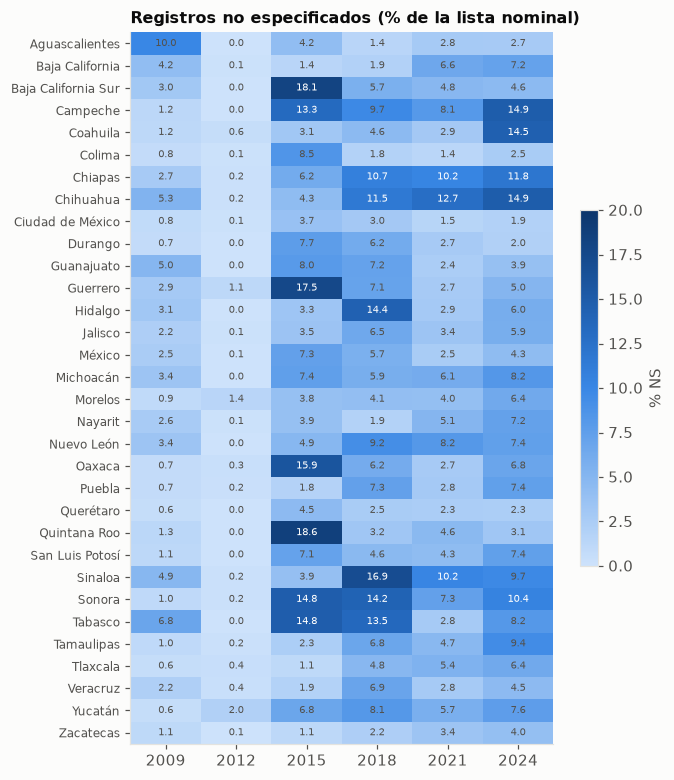

NS nacional (% de LN): {2009: 2.41, 2012: 0.22, 2015: 6.13, 2018: 6.83, 2021: 4.32, 2024: 6.43}


In [10]:
ns_ent = sec.groupby(["EDOCVE", "AELEC"])[["NS", "LN"]].sum().pipe(lambda d: 100 * d.NS / d.LN).unstack()
ns_ent.index = ns_ent.index.map(ENTIDADES)
fig, ax = plt.subplots(figsize=(6.2, 8.4))
im = ax.imshow(ns_ent.values, cmap=CMAP_SEQ, aspect="auto", vmin=0, vmax=20)
ax.set_xticks(range(6), ns_ent.columns); ax.set_yticks(range(32), ns_ent.index, fontsize=8); ax.grid(False)
for i in range(32):
    for j in range(6):
        v = ns_ent.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=6.5, color="white" if v > 10 else TEXTO_2)
ax.set_title("Registros no especificados (% de la lista nominal)")
fig.colorbar(im, ax=ax, shrink=0.5, label="% NS")
plt.show()
print("NS nacional (% de LN):", (100 * nac.NS / nac.LN).round(2).to_dict())

**Cómo leerla.** Cada celda es el porcentaje de la lista nominal sin captura en una entidad y una elección. Más oscuro significa más NS.

**Qué nos dice:**
- El NS cambia mucho entre años: es casi cero en 2012 y alto en 2015 y 2018.
- También cambia entre entidades: llega a 18.6% en Quintana Roo en 2015.
- Si la participación se calculara como SV / LN (tasa «cruda»), los años con mucho NS parecerían de baja participación sin serlo. Por eso se usa SV / (SV + NV).

**¿Cómo se reparte el NS entre secciones?** Lo más delicado son las secciones con 100% de NS, donde la participación no se puede calcular:

In [11]:
sec["p"] = participacion(sec)
sec["r"] = sec.p - sec.AELEC.map(nac.p)                    # participación relativa al nacional (proporción)
sec["ns_share"] = sec.NS / sec.LN
etiquetas = ["0%", "0–5%", "5–20%", "20–50%", "50–<100%", "100%"]
sec["ns_bin"] = pd.cut(sec.ns_share, [-0.001, 0, 0.05, 0.2, 0.5, 0.9999, 1.0], labels=etiquetas)
sec.groupby(["AELEC", "ns_bin"], observed=False).size().unstack()

ns_bin,0%,0–5%,5–20%,20–50%,50–<100%,100%
AELEC,,,,,,
2009,62249,13,130,1154,384,1004
2012,63159,2153,28,144,33,82
2015,61031,134,519,3644,992,2042
2018,59547,141,800,4377,1026,2517
2021,62495,257,617,3086,664,1693
2024,61792,255,828,4675,1101,2100


**¿El NS sesga la participación?** En la fase 1 supusimos que no. La prueba: comparar la participación relativa de cada sección en una elección con el promedio de sus **otras** elecciones. Si el NS fuera aleatorio, las secciones con mucho NS no deberían desviarse de lo habitual.

In [12]:
n_obs = sec.groupby("sid").r.transform("count")
suma = sec.groupby("sid").r.transform("sum")
sec["desvio"] = sec.r - (suma - sec.r) / (n_obs - 1)        # desviación respecto del promedio de las otras elecciones
prueba = sec[(n_obs >= 4) & sec.r.notna() & (sec.ns_share < 0.9999)].groupby("ns_bin", observed=True).desvio.agg(["count", "mean", "std"])
prueba["error estándar"] = prueba["std"] / np.sqrt(prueba["count"])
(prueba[["mean", "std", "error estándar"]] * 100).join(prueba["count"]).rename(
    columns={"count": "casos", "mean": "desviación media (pp)", "std": "desv. estándar (pp)"})

,desviación media (pp),desv. estándar (pp),error estándar,casos
ns_bin,,,,
0%,-0.03,7.81,0.01,363489
0–5%,0.89,5.09,0.09,2903
5–20%,-0.33,7.38,0.14,2841
20–50%,0.36,8.02,0.06,16495
50–<100%,0.57,11.13,0.17,4100


**Qué nos dice:**
- Las desviaciones medias son menores de 1 pp, muy pequeñas frente a la variación normal de 5 a 11 pp, y no crecen con el NS. **El supuesto se sostiene.**
- Con más de 50% de NS la participación sí es más ruidosa (desviación estándar de 11 pp), porque se calcula con pocos registros.

### 3.4 Edades extremas

In [13]:
ne = nac_edad.copy()
ne["grupo"] = pd.cut(ne.EDAD, [17, 89, 99, 109, 200], labels=["18–89", "90–99", "100–109", "110+"])
ed = ne.groupby(["AELEC", "grupo"], observed=True)[CONTEOS].sum()
ed["participación (%)"] = 100 * participacion(ed)
ed["% de la LN"] = 100 * ed.LN / ed.groupby(level=0).LN.transform("sum")
ed[["LN", "participación (%)", "% de la LN"]].unstack(0).round(2)

LN                                                    \
AELEC        2009      2012      2015      2018      2021      2024   
grupo                                                                 
18–89    77097112  76224869  83208336  88717658  93071262  97852065   
90–99      342118    251707    337583    391056    439030    458518   
100–109     40654     13835     17023     14895     21226     19467   
110+         1947       551       520       388       615       298   

        participación (%)                               % de la LN        \
AELEC                2009  2012  2015  2018  2021  2024       2009  2012   
grupo                                                                      
18–89               44.22 62.20 47.18 62.52 51.97 59.80      99.50 99.65   
90–99               13.54 29.81 22.98 28.99 26.17 33.89       0.44  0.33   
100–109              3.29 15.82 10.73 16.35 12.99 18.35       0.05  0.02   
110+                 8.72 18.18 12.53 20.34 16.04 26.06       0.00  0.00   

                                 
AELEC    2015  2018  2021  2024  
grupo                            
18–89   99.58 99.54 99.51 99.51  
90–99    0.40  0.44  0.47  0.47  
100–109  0.02  0.02  0.02  0.02  
110+     0.00  0.00  0.00  0.00

**Qué nos dice:**
- Las personas de 100 años o más son el 0.02% de la lista nominal y votan muy poco.
- Probablemente incluyen registros desactualizados, como personas fallecidas que siguen en la lista.
- No pesan en la participación de las secciones, pero conviene excluirlas del análisis por edad.

### 3.5 ¿Cuántas secciones tienen historia completa?

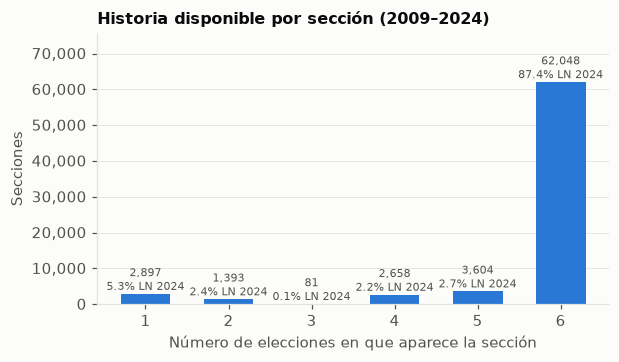

In [14]:
pres = sec.pivot_table(index="sid", columns="AELEC", values="LN", aggfunc="sum").notna()
n_elec = pres.sum(axis=1)
ln24 = sec[sec.AELEC == 2024].set_index("sid").LN
cob = pd.DataFrame({"secciones": n_elec.value_counts().sort_index()})
cob["% LN 2024"] = 100 * ln24.groupby(n_elec).sum() / ln24.sum()

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(cob.index.astype(str), cob.secciones, color=CAT[0], width=0.6)
for x, (s, p) in enumerate(zip(cob.secciones, cob["% LN 2024"])):
    ax.text(x, s, f"{s:,}\n{p:.1f}% LN 2024", ha="center", va="bottom", fontsize=7.5, color=TEXTO_2)
ax.set_xlabel("Número de elecciones en que aparece la sección"); ax.set_ylabel("Secciones")
ax.set_ylim(0, cob.secciones.max() * 1.22); ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}"); ax.grid(axis="x", visible=False)
ax.set_title("Historia disponible por sección (2009–2024)")
plt.show()

**Cómo leerla.** Cada barra cuenta las secciones según en cuántas de las seis elecciones aparecen. El porcentaje es la parte de la lista nominal de 2024 que representan.

**Qué nos dice:**
- 62,048 secciones aparecen en las seis elecciones y suman el **87.4% de la lista nominal de 2024**.
- Las que aparecen una sola vez son, sobre todo, secciones creadas para 2024.

Los patrones de presencia más comunes (● = aparece; orden 2009, 2012, 2015, 2018, 2021, 2024):

In [15]:
patron = pres.apply(lambda f: "".join("●" if v else "·" for v in f), axis=1)
pd.DataFrame({"patrón": patron, "LN 2024": ln24}).groupby("patrón").agg(secciones=("LN 2024", "size"), LN_2024=("LN 2024", "sum")) \
    .sort_values("secciones", ascending=False).head(8).style.format("{:,.0f}")

,secciones,LN_2024
patrón,,
●●●●●●,"62,048","85,936,860"
·····●,"2,775","5,186,932"
··●●●●,"1,922","2,121,126"
·●●●●●,"1,803","2,027,120"
····●●,"1,166","2,349,674"
●·●●●●,"1,004","650,651"
●●●●●·,797,0
●●●●··,722,0


**El hueco de 2012.** El patrón `●·●●●●` llama la atención: secciones que existen antes y después, pero **faltan solo en 2012**. Si fueran cambios de cartografía no reaparecerían igual. La evidencia:

In [16]:
lnp = sec.pivot_table(index="sid", columns="AELEC", values="LN", aggfunc="sum")
hueco12 = lnp[lnp[2009].notna() & lnp[2012].isna() & lnp[2015].notna()].index
r15 = sec[sec.AELEC == 2015].set_index("sid").r
print("Secciones ausentes solo en 2012:", len(hueco12))
print("Lista nominal mediana en 2009 y en 2015:", lnp.loc[hueco12, 2009].median(), lnp.loc[hueco12, 2015].median())
print(f"Participación relativa en 2015: {100 * r15[r15.index.isin(hueco12)].mean():.2f} pp (estas secciones) vs {100 * r15[~r15.index.isin(hueco12)].mean():.2f} pp (resto)")
print("Entidades con más casos:", sec[sec.sid.isin(hueco12) & (sec.AELEC == 2009)].EDOCVE.map(ENTIDADES).value_counts().head(5).to_dict())
print("Lista nominal (millones) de las secciones presentes en las seis elecciones:", (lnp[n_elec == 6].sum() / 1e6).round(2).to_dict())

Secciones ausentes solo en 2012: 1048
Lista nominal mediana en 2009 y en 2015: 519.0 499.5
Participación relativa en 2015: 1.43 pp (estas secciones) vs 1.51 pp (resto)
Entidades con más casos: {'Sinaloa': 256, 'Chihuahua': 155, 'Guerrero': 87, 'Michoacán': 65, 'Tamaulipas': 52}
Lista nominal (millones) de las secciones presentes en las seis elecciones: {2009: 72.02, 2012: 70.62, 2015: 75.41, 2018: 79.44, 2021: 82.63, 2024: 85.94}


**Qué nos dice:**
- Esas secciones tienen el mismo tamaño antes y después, y una participación normal en 2015.
- En 2012 la lista nominal **baja** incluso en las secciones que sí aparecen en las seis elecciones (72.0 → 70.6 → 75.4 millones), y el NS de ese año es casi cero.

La explicación más consistente es que **en 2012 los cuadernillos no capturados se omitieron**, en lugar de contarse como NS. En la fase 3 esa ausencia debe tratarse como dato faltante.

Otros cambios entre elecciones:

In [17]:
g = sec.groupby("sid")
print("Secciones que cambian de tipo (U/M/R):", int((g.TIPOSEC.nunique() > 1).sum()))
print("Secciones que cambian de clave de municipio:", int((g.MPIOCVE.nunique() > 1).sum()))
cambios = (sec.sort_values(["sid", "AELEC"]).assign(antes=lambda d: d.groupby("sid").TIPOSEC.shift())
           .dropna(subset=["antes"]).query("antes != TIPOSEC").groupby(["antes", "TIPOSEC"]).size().rename("transiciones"))
cambios

Secciones que cambian de tipo (U/M/R): 1617
Secciones que cambian de clave de municipio: 254


antes  TIPOSEC
M      R           23
       U          439
R      M          599
       U          290
U      M          348
Name: transiciones, dtype: int64

### 3.6 ¿Las secciones pequeñas son más ruidosas?

En una sección con pocos electores, unos cuantos votos mueven mucho el porcentaje. La pregunta es cuánto de la variación entre elecciones se debe a eso. Se compara la **volatilidad observada** (desviación estándar de la participación relativa en las seis elecciones) con el **ruido que se esperaría solo por azar** dado el tamaño: el error binomial, √(p(1−p)/n).

Lista nominal por sección en 2024 (cuantiles): {0.01: 138.0, 0.1: 383.0, 0.5: 1111.0, 0.9: 2566.0, 0.99: 6332.0}
  secciones 2024 con menos de 100 electores: 68
  secciones 2024 con menos de 200 electores: 2,000
  secciones 2024 con menos de 500 electores: 10,814


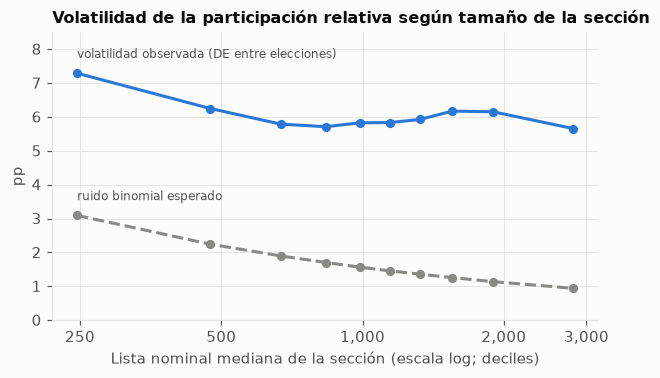

,LN_mediana,volatilidad,ruido_binomial
decil,,,
1,246.50,7.29,3.09
2,474.00,6.25,2.24
3,669.50,5.79,1.90
4,835.50,5.71,1.70
5,986.00,5.83,1.57
6,"1,143.50",5.83,1.46
7,"1,323.50",5.92,1.36
8,"1,552.50",6.17,1.26
9,"1,895.00",6.15,1.14


In [18]:
print("Lista nominal por sección en 2024 (cuantiles):", sec[sec.AELEC == 2024].LN.quantile([.01, .1, .5, .9, .99]).round(0).to_dict())
for u in (100, 200, 500):
    print(f"  secciones 2024 con menos de {u} electores: {(sec[sec.AELEC == 2024].LN < u).sum():,}")

completas = sec[sec.sid.isin(n_elec[n_elec == 6].index)].assign(n_cap=lambda d: d.SV + d.NV)
vs = completas.groupby("sid").agg(LN_med=("LN", "median"), volatilidad=("r", "std"), p_med=("p", "mean"), ncap=("n_cap", "median"))
vs["ruido_binomial"] = np.sqrt(vs.p_med * (1 - vs.p_med) / vs.ncap)
vs["decil"] = pd.qcut(vs.LN_med, 10, labels=False) + 1
tam = vs.groupby("decil").agg(LN_mediana=("LN_med", "median"), volatilidad=("volatilidad", "median"), ruido_binomial=("ruido_binomial", "median"))
tam[["volatilidad", "ruido_binomial"]] *= 100

fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(tam.LN_mediana, tam.volatilidad, marker="o", color=CAT[0])
ax.plot(tam.LN_mediana, tam.ruido_binomial, marker="o", color=GRIS, linestyle="--")
ax.text(tam.LN_mediana.iloc[0], tam.volatilidad.iloc[0] + 0.45, "volatilidad observada (DE entre elecciones)", color=TEXTO_2, fontsize=8)
ax.text(tam.LN_mediana.iloc[0], tam.ruido_binomial.iloc[0] + 0.45, "ruido binomial esperado", color=TEXTO_2, fontsize=8)
ax.set_xscale("log"); ax.set_xticks([250, 500, 1000, 2000, 3000], ["250", "500", "1,000", "2,000", "3,000"]); ax.minorticks_off()
ax.set_xlabel("Lista nominal mediana de la sección (escala log; deciles)"); ax.set_ylabel("pp"); ax.set_ylim(0, 8.5)
ax.set_title("Volatilidad de la participación relativa según tamaño de la sección")
plt.show()
tam

**Cómo leerla.** Las secciones con las seis elecciones se ordenaron por tamaño en 10 grupos (deciles).
- **Línea azul:** cuánto varía en promedio la participación relativa de una sección entre elecciones.
- **Línea gris:** cuánto variaría solo por azar.

**Qué nos dice:**
- La volatilidad es casi la misma en todos los tamaños (5.7–6.2 pp); solo sube en el decil más chico (7.3 pp).
- El ruido por azar es mucho menor (1–3 pp), así que **la mayor parte del vaivén es comportamiento real**, no ruido.
- Basta un umbral mínimo bajo de electores (del orden de 200 a 300) o un encogimiento hacia la media.

### 3.7 ¿El censo (ECEG) y la cartografía cubren nuestras secciones?

In [19]:
s24 = sec[sec.AELEC == 2024][["sid", "LN"]]
en6 = n_elec[n_elec == 6].index
filas = []
for fuente, ids in [("ECEG 2020", set(eceg.sid)), ("Cartografía 2021", set(geo.sid))]:
    for universo, s in [("secciones 2024", s24), ("secciones con las 6 elecciones", s24[s24.sid.isin(en6)])]:
        m = s.sid.isin(ids)
        filas.append({"fuente": fuente, "universo": universo, "secciones": len(s), "% secciones": 100 * m.mean(), "% LN 2024": 100 * s.LN[m].sum() / s.LN.sum()})
display(pd.DataFrame(filas))
nulos = eceg.isna().sum()
print(f"Columnas del ECEG con nulos: {(nulos > 0).sum()}; ¿todos los nulos están en secciones con menos de 50 habitantes? "
      f"{eceg[eceg.POBTOT < 50].isna().sum().sum() == nulos.sum()}")

,fuente,universo,secciones,% secciones,% LN 2024
0,ECEG 2020,secciones 2024,70751,96.08,94.72
1,ECEG 2020,secciones con las 6 elecciones,62048,100.00,100.00
2,Cartografía 2021,secciones 2024,70751,96.08,94.72
3,Cartografía 2021,secciones con las 6 elecciones,62048,100.00,100.00


Columnas del ECEG con nulos: 223; ¿todos los nulos están en secciones con menos de 50 habitantes? True


**Qué nos dice:**
- El ECEG y la cartografía cubren el **100%** de las secciones con historia completa; las que faltan son las creadas después de 2021.
- Los nulos del ECEG están todos en secciones de menos de 50 habitantes: son datos protegidos por confidencialidad.

---
## 4. Exploración de los datos (tarea 2.3)

### 4.1 El ciclo nacional

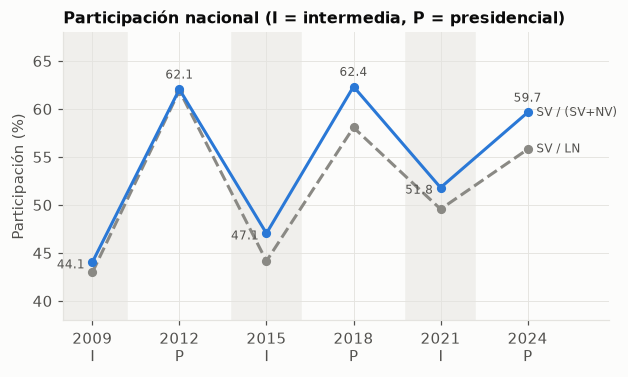

In [20]:
cruda = 100 * nac.SV / nac.LN
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(ELECCIONES, 100 * nac.p, color=CAT[0], marker="o", zorder=3)
ax.plot(ELECCIONES, cruda, color=GRIS, marker="o", linestyle="--", zorder=2)
for a in ELECCIONES:
    abajo = TIPO[a] == "intermedia"
    ax.annotate(f"{100 * nac.p[a]:.1f}", (a, 100 * nac.p[a]), textcoords="offset points", xytext=(-14 if abajo else 0, -4 if abajo else 7),
                ha="center", fontsize=8, color=TEXTO_2)
ax.text(2024.3, 100 * nac.p[2024], "SV / (SV+NV)", va="center", fontsize=8, color=TEXTO_2)
ax.text(2024.3, cruda[2024], "SV / LN", va="center", fontsize=8, color=TEXTO_2)
for a in INTERMEDIAS:
    ax.axvspan(a - 1.2, a + 1.2, color="#f0efec", zorder=0)
ax.set_xticks(ELECCIONES, [ETQ[a] for a in ELECCIONES]); ax.set_xlim(2008, 2026.8); ax.set_ylim(38, 68)
ax.set_ylabel("Participación (%)"); ax.set_title("Participación nacional (I = intermedia, P = presidencial)")
plt.show()

**Cómo leerla:**
- **Línea azul:** participación oficial.
- **Línea gris punteada:** tasa cruda (SV / LN).
- **Bandas grises:** las elecciones intermedias.

**Qué nos dice:**
- La participación **sube en presidenciales (60–62%) y baja en intermedias (44–52%)**. Por eso no se puede comparar una sección entre 2021 y 2024 sin descontar ese ciclo, y se trabaja con participación **relativa al nacional**.
- Las intermedias suben elección tras elección: 44.1%, 47.1%, 51.8%.

### 4.2 Distribución entre secciones

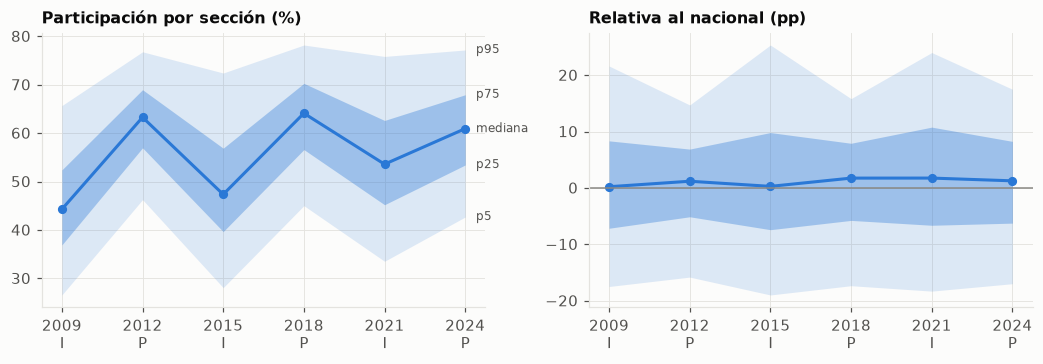

Rango intercuartil por elección (pp): {2009: 15.5, 2012: 12.0, 2015: 17.2, 2018: 13.7, 2021: 17.4, 2024: 14.5}


In [21]:
qs = [.05, .25, .5, .75, .95]
cuant, cuant_r = sec.groupby("AELEC").p.quantile(qs).unstack() * 100, sec.groupby("AELEC").r.quantile(qs).unstack() * 100
fig, axs = plt.subplots(1, 2, figsize=(9.6, 3.4))
for ax, c, titulo in [(axs[0], cuant, "Participación por sección (%)"), (axs[1], cuant_r, "Relativa al nacional (pp)")]:
    ax.fill_between(ELECCIONES, c[.05], c[.95], color=CAT[0], alpha=0.15, linewidth=0)
    ax.fill_between(ELECCIONES, c[.25], c[.75], color=CAT[0], alpha=0.35, linewidth=0)
    ax.plot(ELECCIONES, c[.5], color=CAT[0], marker="o")
    ax.set_xticks(ELECCIONES, [ETQ[a] for a in ELECCIONES]); ax.set_title(titulo)
for q, nom in zip(qs, ["p5", "p25", "mediana", "p75", "p95"]):
    axs[0].text(2024.4, cuant.loc[2024, q], nom, fontsize=8, color=TEXTO_2, va="center")
axs[1].axhline(0, color=GRIS, linewidth=1)
fig.tight_layout(); plt.show()
print("Rango intercuartil por elección (pp):", (cuant[.75] - cuant[.25]).round(1).to_dict())

**Cómo leerla.** La línea es la mediana de las secciones; la banda oscura cubre la mitad central (del percentil 25 al 75) y la clara, del percentil 5 al 95.

**Qué nos dice:**
- A la izquierda todo sube y baja con el ciclo, y la dispersión es mayor en las intermedias.
- A la derecha, en participación relativa, la distribución queda estable y centrada en cero: se elimina el ciclo nacional y queda solo lo propio de cada sección.

### 4.3 Edad y sexo

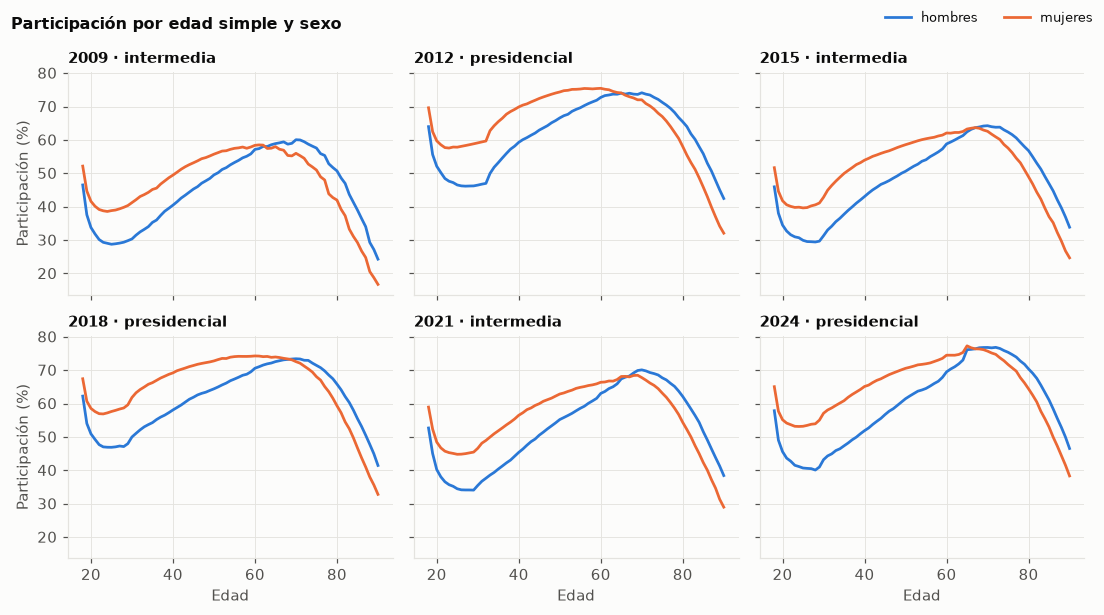

,a los 18,19–20,edad mínima,edad máxima,brecha M−H 25–34,mayor salto 25–35 (edad),mayor salto (pp)
elección,,,,,,,
2009,49.34,39.42,25,65,10.42,35,1.07
2012,66.80,57.49,26,62,12.35,33,3.04
2015,48.82,39.74,26,68,11.32,31,1.92
2018,64.83,56.06,23,67,11.59,30,2.10
2021,55.82,46.53,26,69,11.12,31,1.40
2024,61.46,51.88,25,65,13.52,30,2.13


In [22]:
es = nac_edad[nac_edad.SEXO.isin([0, 1]) & nac_edad.EDAD.between(18, 90)].groupby(["AELEC", "SEXO", "EDAD"])[["SV", "NV"]].sum()
es = (100 * participacion(es)).unstack("SEXO")
es.columns = ["hombres", "mujeres"]
fig, axs = plt.subplots(2, 3, figsize=(10, 5.6), sharex=True, sharey=True)
for ax, a in zip(axs.flat, ELECCIONES):
    ax.plot(es.loc[a].index, es.loc[a].hombres, color=CAT[0], linewidth=1.8)
    ax.plot(es.loc[a].index, es.loc[a].mujeres, color=CAT[1], linewidth=1.8)
    ax.set_title(f"{a} · {TIPO[a]}", fontsize=9.5)
for ax in axs[1]: ax.set_xlabel("Edad")
for ax in axs[:, 0]: ax.set_ylabel("Participación (%)")
fig.legend(["hombres", "mujeres"], loc="upper right", ncol=2, fontsize=8.5)
fig.suptitle("Participación por edad simple y sexo", x=0.01, ha="left", fontsize=10.5, fontweight="bold")
fig.tight_layout(); plt.show()

resumen = []
for a in ELECCIONES:
    d = es.loc[a]; tot = d.mean(axis=1); salto = d.diff().loc[25:35]
    resumen.append({"elección": a, "a los 18": tot[18], "19–20": tot.loc[19:20].mean(), "edad mínima": tot.loc[18:40].idxmin(),
                    "edad máxima": tot.idxmax(), "brecha M−H 25–34": (d.mujeres - d.hombres).loc[25:34].mean(),
                    "mayor salto 25–35 (edad)": salto.mean(axis=1).idxmax(), "mayor salto (pp)": salto.mean(axis=1).max()})
pd.DataFrame(resumen).set_index("elección")

**Qué nos dice:**
- **Primer voto.** A los 18 años la participación es alta. Entre los 19 y 20 cae unos 10 pp, y el mínimo está entre los 23 y 26.
- **Después sube** hasta un máximo entre los 62 y 69 años.
- **Las mujeres votan más que los hombres** hasta alrededor de los 60–65 años; entre los 25 y 34, por 10 a 13.5 pp.
- **Un salto abrupto entre los 30 y 33 años**, de 1.4 a 3 pp de un año de edad al siguiente (columna «mayor salto»). Por lo abrupto, no parece comportamiento; podría ser un efecto administrativo del padrón. Hay que investigarlo antes de definir las bandas de edad.

Para explorar una sola elección, cambia `ELECCION`:

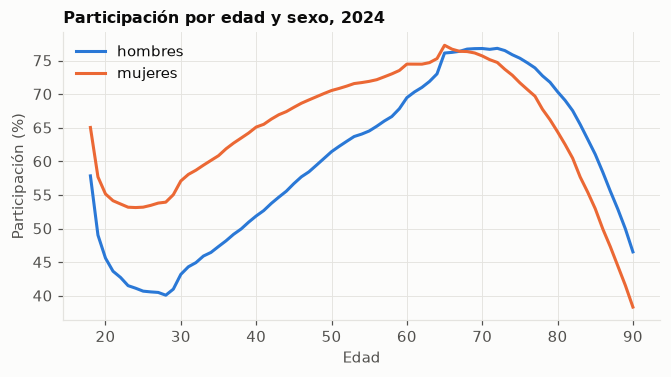

In [23]:
ELECCION = 2024

d = es.loc[ELECCION]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(d.index, d.hombres, color=CAT[0], label="hombres")
ax.plot(d.index, d.mujeres, color=CAT[1], label="mujeres")
ax.set_xlabel("Edad"); ax.set_ylabel("Participación (%)"); ax.legend(); ax.set_title(f"Participación por edad y sexo, {ELECCION}")
plt.show()

### 4.4 Urbano, mixto y rural

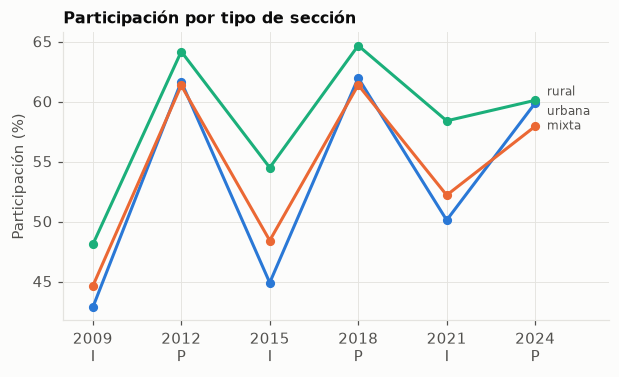

Rural − urbana (pp): {2009: 5.2, 2012: 2.5, 2015: 9.6, 2018: 2.7, 2021: 8.3, 2024: 0.2}


In [24]:
tip = (100 * participacion(sec.groupby(["AELEC", "TIPOSEC"])[["SV", "NV"]].sum())).unstack()
fig, ax = plt.subplots(figsize=(6.4, 3.4))
for c, t, nombre in zip(CAT, ["U", "M", "R"], ["urbana", "mixta", "rural"]):
    ax.plot(ELECCIONES, tip[t], color=c, marker="o")
    ax.text(2024.4, tip.loc[2024, t] + {"R": 0.7, "U": -0.7, "M": 0}[t], nombre, color=TEXTO_2, fontsize=8, va="center")
ax.set_xticks(ELECCIONES, [ETQ[a] for a in ELECCIONES]); ax.set_xlim(2008, 2026.5)
ax.set_ylabel("Participación (%)"); ax.set_title("Participación por tipo de sección")
plt.show()
print("Rural − urbana (pp):", (tip.R - tip.U).round(1).to_dict())

**Qué nos dice:**
- Las secciones **rurales votan más**, sobre todo en intermedias: de 5 a 10 pp más que las urbanas.
- En las presidenciales la diferencia casi desaparece.
- El vaivén entre tipos de elección es más fuerte en las ciudades, y el tipo de sección es candidato para el árbol de decisión de la fase 4.

### 4.5 ¿Qué forma tienen las trayectorias?

Esta es la sección más importante para el modelado. Se construye el **panel de trayectorias**: las secciones con las seis elecciones y participación definida en todas, con la participación relativa en pp.

In [25]:
P = sec.pivot_table(index="sid", columns="AELEC", values="r") * 100
T = P.loc[n_elec[n_elec == 6].index].dropna().astype("float64")
meta = sec[sec.AELEC == 2024].set_index("sid")[["EDOCVE", "MPIOCVE", "LN"]].assign(mun=lambda d: d.EDOCVE * 1000 + d.MPIOCVE)
print(f"Secciones en las seis elecciones: {(n_elec == 6).sum():,}; con participación definida en las seis: {len(T):,} "
      f"({(n_elec == 6).sum() - len(T):,} tienen alguna elección con 100% de NS)")
T.head()

Secciones en las seis elecciones: 62,048; con participación definida en las seis: 54,892 (7,156 tienen alguna elección con 100% de NS)


AELEC,2009,2012,2015,2018,2021,2024
sid,,,,,,
10001,9.24,10.76,6.95,15.83,28.93,19.91
10002,2.02,1.41,-7.45,-9.46,3.15,-1.25
10003,2.53,9.79,-2.18,7.65,5.44,12.22
10004,5.78,9.35,-6.78,5.34,5.56,11.45
10005,6.34,10.63,-2.97,8.70,10.90,6.24


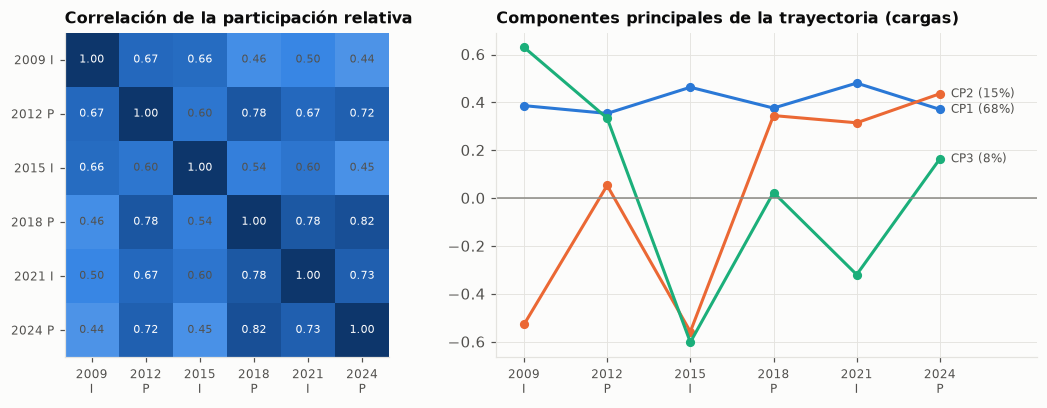

Varianza explicada: CP1 **68%**, CP2 **15%**, CP3 **8%**. El nivel medio explica **67%** de la varianza total y la forma **33%**.

,CP1,CP2,CP3
2009,0.39,-0.53,0.63
2012,0.35,0.05,0.33
2015,0.46,-0.56,-0.60
2018,0.38,0.35,0.02
2021,0.48,0.31,-0.32
2024,0.37,0.44,0.16


In [26]:
from sklearn.decomposition import PCA

C_corr = T.corr()
pca = PCA().fit(T.values)
var = pca.explained_variance_ratio_
signo = np.sign(pca.components_[:3].sum(axis=1))                   # orientación: CP con suma positiva
cargas = pd.DataFrame((pca.components_[:3] * signo[:, None]).T, index=ELECCIONES, columns=["CP1", "CP2", "CP3"])
nivel = T.mean(axis=1)
forma = T.sub(nivel, axis=0)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [1, 1.25]})
axs[0].imshow(C_corr.values, cmap=CMAP_SEQ, vmin=0, vmax=1)
axs[0].set_xticks(range(6), [ETQ[a] for a in ELECCIONES], fontsize=8); axs[0].set_yticks(range(6), [ETQ[a].replace("\n", " ") for a in ELECCIONES], fontsize=8)
axs[0].grid(False)
for i in range(6):
    for j in range(6):
        axs[0].text(j, i, f"{C_corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7.5, color="white" if C_corr.values[i, j] > 0.6 else TEXTO_2)
axs[0].set_title("Correlación de la participación relativa")
for k, (c, nom) in enumerate(zip(CAT, ["CP1", "CP2", "CP3"])):
    axs[1].plot(ELECCIONES, cargas[nom], color=c, marker="o")
    axs[1].text(2024.4, cargas.loc[2024, nom], f"{nom} ({100 * var[k]:.0f}%)", color=TEXTO_2, fontsize=8, va="center")
axs[1].axhline(0, color=GRIS, linewidth=1); axs[1].set_xticks(ELECCIONES, [ETQ[a] for a in ELECCIONES], fontsize=8); axs[1].set_xlim(2008, 2027.5)
axs[1].set_title("Componentes principales de la trayectoria (cargas)")
fig.tight_layout(); plt.show()
display(Markdown(f"Varianza explicada: CP1 **{var[0]:.0%}**, CP2 **{var[1]:.0%}**, CP3 **{var[2]:.0%}**. "
                 f"El nivel medio explica **{6 * nivel.var() / T.var().sum():.0%}** de la varianza total y la forma **{forma.var().sum() / T.var().sum():.0%}**."))
cargas

**Cómo leerla:**
- **Izquierda:** correlación entre las participaciones relativas de cada par de elecciones. Más oscuro, más parecidas.
- **Derecha:** los tres componentes principales (CP). Cada línea muestra cuánto pesa cada elección en ese componente.

**Qué nos dice:**
- **Las presidenciales se parecen mucho entre sí (0.72–0.82); las intermedias, menos (0.50–0.66).**
- **CP1 (68%) es el nivel.** Pesa casi igual en las seis elecciones: secciones que votan mucho, o poco, siempre.
- **CP2 (15%) es el cambio entre periodos.** Opone 2009 y 2015 a 2018–2024: secciones que mejoran o se deterioran.
- **CP3 (8%) son choques de intermedias concretas.** Opone 2009 a 2015 y 2021.

**Implicación clave para la fase 3:**
- Dos terceras partes de la diferencia entre secciones es solo «cuánto votan».
- Si se agrupan las trayectorias tal cual, los grupos serán *alta, media y baja participación*.
- Hay que **separar el nivel de la forma** antes de agrupar.

**El problema con datos reales.** Se eligen cuatro secciones con **el mismo nivel medio** (a menos de 1 pp del nacional) y al menos 800 electores. Se toman en el percentil 97 de cada rasgo, no en el máximo, para no mostrar casos anómalos.

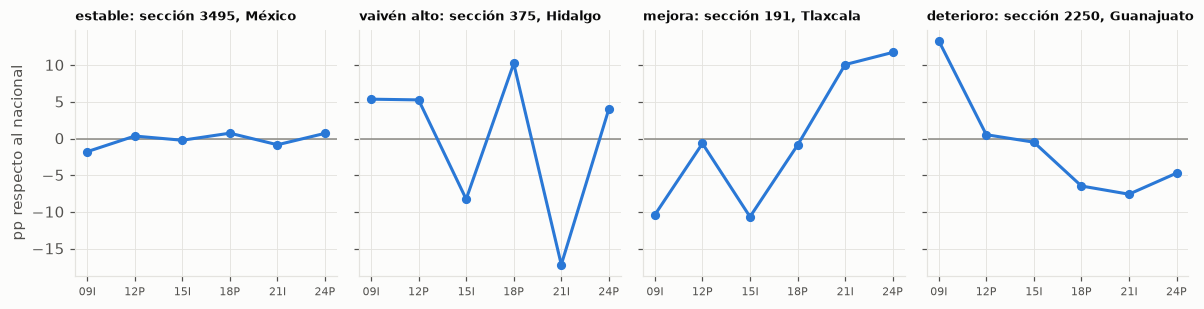

In [27]:
vaiven = T[PRESIDENCIALES].mean(axis=1) - T[INTERMEDIAS].mean(axis=1)
tendencia = pd.Series(np.polyfit(np.arange(6), T.T.values, 1)[0], index=T.index)      # pp por elección
cerca0 = T.index[(nivel.abs() < 1) & (meta.LN.reindex(T.index) >= 800)]


def en_percentil(serie, q):
    return (serie - serie.quantile(q)).abs().idxmin()


ejemplos = {"estable": forma.loc[cerca0].abs().max(axis=1).idxmin(), "vaivén alto": en_percentil(vaiven.loc[cerca0], 0.97),
            "mejora": en_percentil(tendencia.loc[cerca0], 0.97), "deterioro": en_percentil(tendencia.loc[cerca0], 0.03)}
fig, axs = plt.subplots(1, 4, figsize=(11, 2.9), sharey=True)
for ax, (nom, s) in zip(axs, ejemplos.items()):
    ax.axhline(0, color=GRIS, linewidth=1)
    ax.plot(ELECCIONES, T.loc[s], color=CAT[0], marker="o")
    ax.set_title(f"{nom}: sección {s % 10000}, {ENTIDADES[int(meta.loc[s, 'EDOCVE'])]}", fontsize=8.5)
    ax.set_xticks(ELECCIONES, [CORTA[a] for a in ELECCIONES], fontsize=7.5)
axs[0].set_ylabel("pp respecto al nacional")
fig.tight_layout(); plt.show()

Las cuatro tienen el mismo promedio, pero historias muy distintas: una estable, una con vaivén fuerte, una que mejora y una que se deteriora. Un promedio no las distingue; un análisis de trayectorias sí. Esta es la motivación del proyecto, vista en los datos.

### 4.6 Geografía

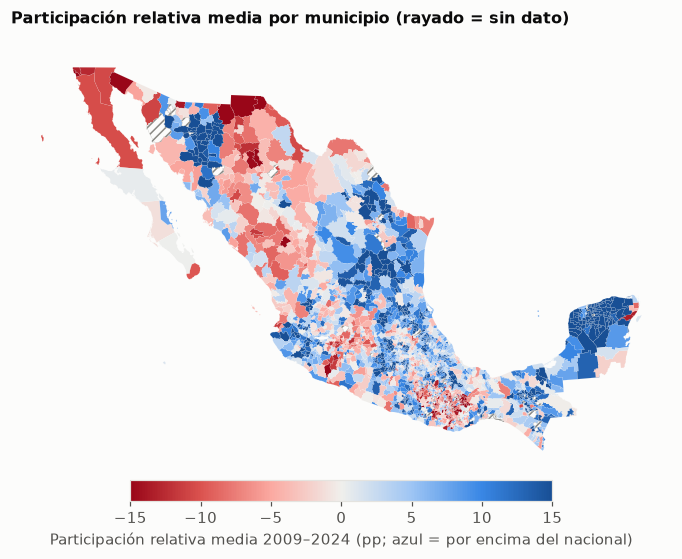

In [28]:
w = sec[sec.sid.isin(T.index)].assign(mun=lambda d: d.EDOCVE * 1000 + d.MPIOCVE).groupby(["mun", "AELEC"])[["SV", "NV"]].sum()
w["r"] = 100 * (participacion(w) - w.index.get_level_values("AELEC").map(nac.p).values)
mapa = muni.assign(mun=muni.ENTIDAD.astype("int64") * 1000 + muni.MUNICIPIO.astype("int64")).merge(
    w.r.unstack().mean(axis=1).rename("r_media"), left_on="mun", right_index=True, how="left")
fig, ax = plt.subplots(figsize=(9, 6))
mapa.plot(column="r_media", cmap=CMAP_DIV, vmin=-15, vmax=15, ax=ax, linewidth=0.05, edgecolor="#fcfcfb",
          missing_kwds={"color": "#fcfcfb", "edgecolor": "#8a8984", "hatch": "////", "linewidth": 0.1})
ax.set_axis_off()
cb = fig.colorbar(plt.cm.ScalarMappable(cmap=CMAP_DIV, norm=plt.Normalize(-15, 15)), ax=ax, shrink=0.55, orientation="horizontal", pad=0.02)
cb.set_label("Participación relativa media 2009–2024 (pp; azul = por encima del nacional)")
ax.set_title("Participación relativa media por municipio (rayado = sin dato)")
plt.show()

**Cómo leerla.** Azul, por encima del nacional; rojo, por debajo; rayado, sin dato.

¿Qué tanto de la variación entre secciones se explica solo por la entidad o el municipio donde están?

In [29]:
m = meta.reindex(T.index)
filas = [("nivel (media de las 6 elecciones)", nivel), ("vaivén presidencial − intermedia", vaiven)] + [(f"participación relativa {a}", T[a]) for a in ELECCIONES]
pd.DataFrame([{"variable": n, "R² entidad": r2_grupo(y, m.EDOCVE), "R² municipio": r2_grupo(y, m.mun)} for n, y in filas]).set_index("variable")

,R² entidad,R² municipio
variable,,
nivel (media de las 6 elecciones),0.26,0.63
vaivén presidencial − intermedia,0.51,0.81
participación relativa 2009,0.39,0.71
participación relativa 2012,0.29,0.59
participación relativa 2015,0.37,0.73
participación relativa 2018,0.34,0.63
participación relativa 2021,0.22,0.65
participación relativa 2024,0.28,0.59


**Qué nos dice:**
- **El nivel tiene un patrón regional claro.** El municipio explica el 64% de sus diferencias.
- **El vaivén es todavía más territorial.** El municipio explica el 81% y la entidad el 51%. Podría deberse a las elecciones locales que coinciden con las federales, que cambian por entidad y año; no se verificó aquí, pero es una variable candidata para el árbol.

### 4.7 ¿Qué rasgos persisten en el tiempo? (prueba preliminar de H2 y H3)

Un perfil solo sirve para planear si describe algo **estable** de la sección. La prueba: calcular cada rasgo en dos periodos sin elecciones en común y ver si las secciones conservan su posición. En la fase 1 se fijó 0.5 como umbral de correlación.

Primero se calculan las brechas por sección, relativas a la brecha nacional de cada elección:
- **Brecha de jóvenes:** participación de 18–34 años menos la de 55–74.
- **Brecha de género:** mujeres menos hombres, de 18 a 54 años.

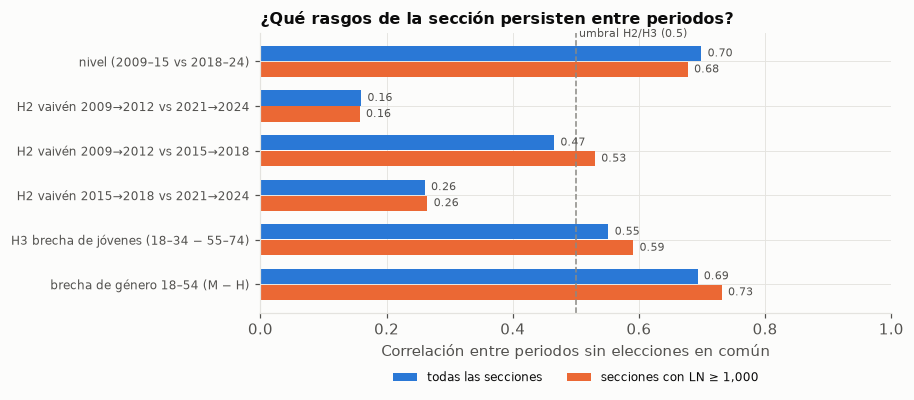

,r (todas),"r (LN ≥ 1,000)",secciones
rasgo,,,
nivel (2009–15 vs 2018–24),0.70,0.68,54892
H2 vaivén 2009→2012 vs 2021→2024,0.16,0.16,54892
H2 vaivén 2009→2012 vs 2015→2018,0.47,0.53,54892
H2 vaivén 2015→2018 vs 2021→2024,0.26,0.26,54892
H3 brecha de jóvenes (18–34 − 55–74),0.55,0.59,54891
brecha de género 18–54 (M − H),0.69,0.73,54892


In [30]:
s6 = se[se.sid.isin(T.index) & se.SEXO.isin([0, 1])].copy()
s6["grupo"] = s6.BANDA.map({"18-24": "joven", "25-34": "joven", "55-64": "mayor", "65-74": "mayor"})
gj = s6.dropna(subset=["grupo"]).groupby(["sid", "AELEC", "grupo"])[["SV", "NV"]].sum()
pj = participacion(gj).unstack("grupo")
nj = participacion(gj.groupby(["AELEC", "grupo"]).sum()).unstack()
brecha_joven = ((pj.joven - pj.mayor) - pj.index.get_level_values("AELEC").map(nj.joven - nj.mayor).values).unstack() * 100

gs = s6[s6.BANDA.isin(["18-24", "25-34", "35-44", "45-54"])].groupby(["sid", "AELEC", "SEXO"])[["SV", "NV"]].sum()
ps = participacion(gs).unstack("SEXO")
ns_ = participacion(gs.groupby(["AELEC", "SEXO"]).sum()).unstack()
brecha_genero = ((ps[1] - ps[0]) - ps.index.get_level_values("AELEC").map(ns_[1] - ns_[0]).values).unstack() * 100

A, B = [2009, 2012, 2015], [2018, 2021, 2024]
pruebas = {
    "nivel (2009–15 vs 2018–24)": (T[A].mean(axis=1), T[B].mean(axis=1)),
    "H2 vaivén 2009→2012 vs 2021→2024": (T[2012] - T[2009], T[2024] - T[2021]),
    "H2 vaivén 2009→2012 vs 2015→2018": (T[2012] - T[2009], T[2018] - T[2015]),
    "H2 vaivén 2015→2018 vs 2021→2024": (T[2018] - T[2015], T[2024] - T[2021]),
    "H3 brecha de jóvenes (18–34 − 55–74)": (brecha_joven[A].mean(axis=1), brecha_joven[B].mean(axis=1)),
    "brecha de género 18–54 (M − H)": (brecha_genero[A].mean(axis=1), brecha_genero[B].mean(axis=1)),
}
filas = []
for nombre, (a, b) in pruebas.items():
    d = pd.concat([a, b], axis=1).dropna()
    grandes = meta.LN.reindex(d.index) >= 1000
    filas.append({"rasgo": nombre, "r (todas)": d.corr().iloc[0, 1], "r (LN ≥ 1,000)": d[grandes].corr().iloc[0, 1], "secciones": len(d)})
pers = pd.DataFrame(filas)

fig, ax = plt.subplots(figsize=(7.4, 3.3))
y = np.arange(len(pers))[::-1]
b1 = ax.barh(y + 0.18, pers["r (todas)"], height=0.34, color=CAT[0], label="todas las secciones")
b2 = ax.barh(y - 0.18, pers["r (LN ≥ 1,000)"], height=0.34, color=CAT[1], label="secciones con LN ≥ 1,000")
for yy, v1, v2 in zip(y, pers["r (todas)"], pers["r (LN ≥ 1,000)"]):
    ax.text(v1 + 0.01, yy + 0.18, f"{v1:.2f}", va="center", fontsize=7.5, color=TEXTO_2)
    ax.text(v2 + 0.01, yy - 0.18, f"{v2:.2f}", va="center", fontsize=7.5, color=TEXTO_2)
ax.axvline(0.5, color=GRIS, linestyle="--", linewidth=1); ax.text(0.505, y.max() + 0.55, "umbral H2/H3 (0.5)", fontsize=7.5, color=TEXTO_2)
ax.set_yticks(y, pers.rasgo, fontsize=8); ax.set_xlim(0, 1); ax.set_xlabel("Correlación entre periodos sin elecciones en común")
ax.legend(handles=[b1, b2], loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, fontsize=8)
ax.set_title("¿Qué rasgos de la sección persisten entre periodos?")
plt.show()
pers.set_index("rasgo")

**Qué nos dice:**
- **Persisten:** el nivel (0.70), la brecha de género (0.69) y la brecha de jóvenes (0.55). **H3, «jóvenes ausentes», pasa** la prueba preliminar.
- **No persiste el vaivén** entre presidencial e intermedia (0.16 entre 2009→2012 y 2021→2024). **H2, «solo presidenciales», falla:** una sección que oscila mucho en un periodo no necesariamente oscila en otro. Se confirma el hallazgo del hackathon: la intermitencia no es un rasgo estable del territorio.

### 4.8 Regresión a la media (antecedente de H5, «en deterioro»)

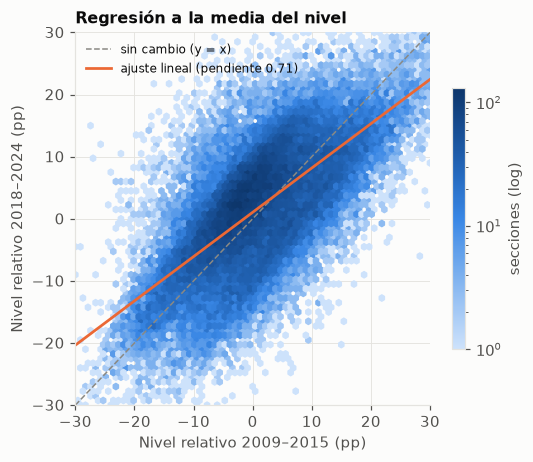

Pendiente: 0.71 | DE del residuo: 7.2 pp | secciones con residuo < −5 pp: 23%
R² del residuo explicado por el municipio: 0.68; por la entidad: 0.40


In [31]:
a_, b_ = T[A].mean(axis=1), T[B].mean(axis=1)
pendiente, ordenada = np.polyfit(a_, b_, 1)
residuo = b_ - (ordenada + pendiente * a_)

fig, ax = plt.subplots(figsize=(5.2, 4.4))
hb = ax.hexbin(a_, b_, gridsize=70, cmap=CMAP_SEQ, mincnt=1, bins="log", extent=(-30, 30, -30, 30))
lim = np.array([-30, 30])
ax.plot(lim, lim, color=GRIS, linestyle="--", linewidth=1, label="sin cambio (y = x)")
ax.plot(lim, ordenada + pendiente * lim, color=CAT[1], linewidth=1.8, label=f"ajuste lineal (pendiente {pendiente:.2f})")
ax.legend(loc="upper left", fontsize=8); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Nivel relativo 2009–2015 (pp)"); ax.set_ylabel("Nivel relativo 2018–2024 (pp)"); ax.set_title("Regresión a la media del nivel")
fig.colorbar(hb, ax=ax, shrink=0.7, label="secciones (log)")
plt.show()
print(f"Pendiente: {pendiente:.2f} | DE del residuo: {residuo.std():.1f} pp | secciones con residuo < −5 pp: {100 * (residuo < -5).mean():.0f}%")
print(f"R² del residuo explicado por el municipio: {r2_grupo(residuo, m.mun):.2f}; por la entidad: {r2_grupo(residuo, m.EDOCVE):.2f}")

**Cómo leerla.** Cada punto es una sección: su nivel relativo en 2009–2015 (eje X) contra el de 2018–2024 (eje Y). La línea punteada es «sin cambio» y la naranja, el ajuste real.

**Qué nos dice:**
- La pendiente es 0.71, menor que 1: las secciones extremas tienden a acercarse al promedio aunque nada cambie en ellas (**regresión a la media**).
- Por eso, para H5 hay que medir la caída **respecto de lo esperado**, el residuo de la recta, como se definió en la fase 1.
- El municipio explica el 68% de ese residuo: los cambios son sobre todo municipales.

---
## 5. Elección de la fuente municipal del CONEVAL (actividad 2.5)

En la fase 1 quedaron dos candidatas para el contexto municipal: el **Índice de Rezago Social (IRS)** y la **medición de pobreza**. Se decide con los criterios C1 a C5 fijados entonces, **sin mirar su relación con la participación**, para no elegir la fuente que «da el resultado que queremos».

### 5.1 Lectura de los archivos del CONEVAL

Los archivos son hojas de Excel con encabezados de varios renglones y notas al pie, así que se toman solo los renglones con clave de municipio de 5 dígitos. La pobreza trae un renglón de grupo («Pobreza», «Pobreza extrema», …) y otro de subcolumna («Porcentaje 2010», …), que se combinan en un solo nombre.

In [32]:
IRS_IND = ["analfabeta_15", "no_asiste_6_14", "basica_incompleta_15", "sin_derechohabiencia", "piso_tierra", "sin_excusado",
           "sin_agua_entubada", "sin_drenaje", "sin_electricidad", "sin_lavadora", "sin_refrigerador"]


def norm_txt(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()
    return re.sub(r"[^a-z0-9]+", "_", s).strip("_")


z = zipfile.ZipFile(RAW / "coneval" / "IRS_ent_mun_2000_2020.zip")
partes = []
for anio in (2010, 2015, 2020):
    d = pd.read_excel(io.BytesIO(z.read(f"IRS_entidades_mpios_{anio}.xlsx")), sheet_name="Municipios", header=None, dtype=str)
    d = d[d[2].fillna("").str.strip().str.fullmatch(r"\d{4,5}")].iloc[:, :19]
    d.columns = ["ent", "nom_ent", "mun_inegi", "nom_mun", "poblacion"] + IRS_IND + ["irs", "grado", "lugar"]
    d = d.assign(mun_inegi=d.mun_inegi.astype(int), anio=anio)
    for c in ["poblacion"] + IRS_IND + ["irs"]:
        d[c] = pd.to_numeric(d[c], errors="coerce")
    partes.append(d)
irs = pd.concat(partes, ignore_index=True)

z = zipfile.ZipFile(RAW / "coneval" / "pobreza_municipal_2010_2020.zip")
d = pd.read_excel(io.BytesIO(z.read(z.namelist()[0])), sheet_name="Concentrado municipal", header=None, dtype=str)
grupo, sub = d.iloc[4].ffill(), d.iloc[5]
d.columns = [norm_txt(grupo[j]) if j <= 4 or pd.isna(sub[j]) else f"{norm_txt(grupo[j])}|{norm_txt(sub[j])}" for j in range(d.shape[1])]
d = d[d.clave_de_municipio.fillna("").str.strip().str.fullmatch(r"\d{4,5}")].copy()
d["mun_inegi"] = d.clave_de_municipio.astype(int)
largo = []
for anio in (2010, 2015, 2020):
    sel = {c: c.split("|")[0] for c in d.columns if c.endswith(f"|porcentaje_{anio}")}
    x = d[["mun_inegi", "municipio"] + list(sel)].rename(columns=sel)
    x[list(sel.values())] = x[list(sel.values())].apply(pd.to_numeric, errors="coerce")   # 'n.a.' → NaN
    largo.append(x.assign(anio=anio))
pob = pd.concat(largo, ignore_index=True)
print("IRS, municipios por año:", irs.groupby("anio").irs.count().to_dict())
print("Pobreza, municipios por año:", pob.groupby("anio").pobreza.count().to_dict())
print("Indicadores de pobreza:", [c for c in pob.columns if c not in ("mun_inegi", "municipio", "anio")])

IRS, municipios por año: {2010: 2456, 2015: 2446, 2020: 2469}
Pobreza, municipios por año: {2010: 2456, 2015: 2446, 2020: 2466}
Indicadores de pobreza: ['pobreza', 'pobreza_extrema', 'pobreza_moderada', 'vulnerables_por_carencia_social', 'vulnerables_por_ingreso', 'no_pobre_y_no_vulnerable', 'rezago_educativo', 'carencia_por_acceso_a_los_servicios_de_salud', 'carencia_por_acceso_a_la_seguridad_social', 'carencia_por_calidad_y_espacios_de_la_vivienda', 'carencia_por_acceso_a_los_servicios_basicos_en_la_vivienda', 'carencia_por_acceso_a_la_alimentacion', 'poblacion_con_al_menos_una_carencia_social', 'poblacion_con_tres_o_mas_carencias_sociales', 'poblacion_con_ingreso_inferior_a_la_linea_de_pobreza_por_ingresos', 'poblacion_con_ingreso_inferior_a_la_linea_de_pobreza_extrema_por_ingresos']


### 5.2 Cruce de claves de municipio INE → INEGI

El CONEVAL usa claves del INEGI y los conteos, claves del INE. ¿Cuántas coinciden? Se unen por **nombre dentro de cada entidad**, en cuatro pasos:
1. **Nombre exacto.** Se usan como alias todas las variantes de nombre de cada clave, porque hay municipios renombrados. Si un nombre se repite en la entidad (los dos «San Juan Mixtepec» de Oaxaca), se emparejan en orden.
2. **Nombre aproximado.** Corrige errores de captura.
3. **Nombre contenido en el otro.** Cubre versiones largas y cortas del mismo nombre.
4. **Municipios creados después de 2020.** No tienen dato del CONEVAL; se les asigna el municipio del que se separaron, inferido de los propios conteos (al que pertenecían sus secciones antes).

In [33]:
def norm_mun(s):
    s = unicodedata.normalize("NFKD", str(s).lower()).encode("ascii", "ignore").decode()
    s = re.sub(r"\b(de|del|la|las|los|el|y|heroica|villa|ciudad|h)\b", " ", s)
    return re.sub(r"[^a-z0-9]", "", s)


sec["mun"] = sec.EDOCVE.astype("int64") * 1000 + sec.MPIOCVE.astype("int64")
ine = sec.sort_values("AELEC").groupby("mun").agg(ent=("EDOCVE", "last"), nom_ine=("MPIONOM", "last")).reset_index()
ine["n"] = ine.nom_ine.map(norm_mun)
alias = pd.concat([irs[["mun_inegi", "nom_mun"]].rename(columns={"nom_mun": "nom"}), pob[["mun_inegi", "municipio"]].rename(columns={"municipio": "nom"})]).dropna()
alias["nom"] = alias.nom.str.replace(r"\s*-\s*Dto\.?\s*\d+\s*-?", "", regex=True)
alias = alias.assign(n=alias.nom.map(norm_mun), ent=alias.mun_inegi // 1000).drop_duplicates(["mun_inegi", "n"])

asign = {}
for ent_, g in ine.groupby("ent"):
    por_nombre = alias[alias.ent == ent_].groupby("n").mun_inegi.apply(lambda s: sorted(set(s))).to_dict()
    for n, gg in g.groupby("n"):                                              # 1) exacto
        if n in por_nombre:
            a_ord, b_ord = sorted(gg.mun), por_nombre[n]
            if len(a_ord) == len(b_ord):
                asign.update({a: (b, "exacto") for a, b in zip(a_ord, b_ord)})
            else:
                asign.update({a: (min(b_ord, key=lambda b: abs(b % 1000 - a % 1000)), "exacto_ambiguo") for a in a_ord})
    for _, r in g[~g.mun.isin(asign)].iterrows():
        cerca = difflib.get_close_matches(r.n, list(por_nombre), 1, 0.85)      # 2) aproximado
        if cerca:
            asign[r.mun] = (min(por_nombre[cerca[0]], key=lambda b: abs(b % 1000 - r.mun % 1000)), "aproximado"); continue
        cont = sorted((k for k in por_nombre if len(k) >= 5 and (k in r.n or r.n in k)), key=len, reverse=True)
        if cont and (len(cont) == 1 or len(cont[0]) > len(cont[1])):         # 3) contenido
            asign[r.mun] = (por_nombre[cont[0]][0], "contenido")
for mu in [x for x in ine.mun if x not in asign]:                          # 4) municipio de origen
    ids = sec[sec.mun == mu].sid.unique()
    antes = sec[sec.sid.isin(ids) & (sec.mun != mu)]
    if len(antes):
        origen = antes[antes.AELEC == antes.AELEC.max()].mun.mode()[0]
        if origen in asign:
            asign[mu] = (asign[origen][0], "municipio_origen")

cruce = ine[["mun", "nom_ine"]].rename(columns={"mun": "mun_ine"})
cruce["mun_inegi"] = cruce.mun_ine.map(lambda x: asign.get(x, (np.nan, ""))[0])
cruce["método"] = cruce.mun_ine.map(lambda x: asign.get(x, (np.nan, "sin_cruce"))[1])
nombre_inegi = irs.sort_values("anio", ascending=False).drop_duplicates("mun_inegi").set_index("mun_inegi").nom_mun
cruce["nom_inegi"] = cruce.mun_inegi.map(nombre_inegi)
print(f"Claves INE iguales a las INEGI: {100 * (cruce.mun_ine == cruce.mun_inegi).mean():.1f}%")
print("Método de cruce:", cruce["método"].value_counts().to_dict())
print("Claves INEGI asignadas a más de un municipio INE (sin contar los de origen):",
      int(cruce[cruce["método"] != "municipio_origen"].mun_inegi.dropna().duplicated(keep=False).sum()))
cruce[cruce["método"] != "exacto"]

Claves INE iguales a las INEGI: 44.6%
Método de cruce: {'exacto': 2459, 'municipio_origen': 8, 'aproximado': 5, 'contenido': 5}
Claves INEGI asignadas a más de un municipio INE (sin contar los de origen): 0


,mun_ine,nom_ine,mun_inegi,método,nom_inegi
17,2007,San Felipe,2002,municipio_origen,Mexicali
28,4006,Hopelche}én,4006,aproximado,Hopelchén
34,4012,Dzitbalché,4001,municipio_origen,Calkiní
121,7038,Huitiupaán,7039,aproximado,Huitiupán
190,7107,Villacomaltitlán,7071,contenido,Villa Comaltitlán
296,10006,Simón Bolívar,10006,contenido,General Simón Bolívar
457,12082,Ñuu Savi,12012,municipio_origen,Ayutla de los Libres
458,12083,Las Vigas,12053,municipio_origen,San Marcos
459,12084,San Nicolás,12023,municipio_origen,Cuajinicuilapa
460,12085,Santa Cruz del Rincón,12041,municipio_origen,Malinaltepec


**Qué nos dice:**
- Menos de la mitad de las claves coinciden. **Sin este cruce, unir el CONEVAL por clave habría asignado datos de otro municipio** a más de la mitad de las secciones.
- Todos los municipios quedan cruzados y ninguna clave INEGI se asigna dos veces.

### 5.3 C1. Cobertura

Porcentaje de municipios, y de la lista nominal 2024 de las secciones con las seis elecciones, que tiene dato en cada fuente y año (umbral de la fase 1: 98% de la lista nominal):

In [34]:
s6_24 = sec[(sec.AELEC == 2024) & sec.sid.isin(n_elec[n_elec == 6].index)][["sid", "mun", "LN"]].merge(
    cruce[["mun_ine", "mun_inegi"]], left_on="mun", right_on="mun_ine", how="left")
filas = []
for fuente, df, v in [("IRS", irs, "irs"), ("Pobreza", pob, "pobreza")]:
    for anio in (2010, 2015, 2020):
        con = set(df[(df.anio == anio) & df[v].notna()].mun_inegi)
        mm = s6_24.mun_inegi.isin(con)
        filas.append({"fuente": fuente, "año": anio, "% municipios": 100 * s6_24.drop_duplicates("mun").mun_inegi.isin(con).mean(),
                      "% LN 2024": 100 * s6_24.LN[mm].sum() / s6_24.LN.sum()})
pd.DataFrame(filas).pivot(index="año", columns="fuente")

% municipios         % LN 2024        
fuente          IRS Pobreza       IRS Pobreza
año                                          
2010          99.47   99.47     99.72   99.72
2015          99.07   99.07     99.62   99.62
2020         100.00   99.88    100.00   99.96

Las dos fuentes cubren más del 99% de la lista nominal: **ambas pasan C1**.

### 5.4 C2. Comparabilidad en el tiempo

Según los propios documentos del CONEVAL:
- **IRS** (nota de resultados 2020): «no es posible realizar un análisis del comportamiento del índice o del grado de rezago entre los periodos». Cada año se calcula por separado.
- **Pobreza** (metodología municipal 2020): «serie quinquenal comparable 2010-2020», con la misma metodología.

Las dos son estables entre años (alta correlación), pero solo la pobreza permite medir **cambios**:

In [35]:
filas = []
for nombre, df, v in [("IRS (índice)", irs, "irs"), ("Pobreza (%)", pob, "pobreza"), ("Pobreza extrema (%)", pob, "pobreza_extrema")]:
    w = df.pivot_table(index="mun_inegi", columns="anio", values=v)
    filas.append({"indicador": nombre, "r 2010–2015": w[[2010, 2015]].corr().iloc[0, 1], "r 2015–2020": w[[2015, 2020]].corr().iloc[0, 1],
                  "r 2010–2020": w[[2010, 2020]].corr().iloc[0, 1], "media 2010": w[2010].mean(), "media 2020": w[2020].mean()})
pd.DataFrame(filas).set_index("indicador")

,r 2010–2015,r 2015–2020,r 2010–2020,media 2010,media 2020
indicador,,,,,
IRS (índice),0.97,0.98,0.96,0.00,0.00
Pobreza (%),0.93,0.92,0.90,67.01,62.00
Pobreza extrema (%),0.91,0.91,0.88,25.52,17.24


### 5.5 C3. ¿Qué aporta cada fuente que el censo por sección no tenga?

El ECEG ya trae educación, salud, vivienda y bienes por sección. Si un indicador del CONEVAL se reconstruye casi perfecto con el ECEG, no aporta nada nuevo. El procedimiento:
1. Se agregan **29 indicadores del ECEG al municipio**, sumando numeradores y denominadores (no promediando porcentajes).
2. Se predice cada indicador del CONEVAL 2020 con una regresión ridge y con gradient boosting.
3. Se evalúa con **validación cruzada por entidad**: se entrena con unas entidades y se evalúa en otras, para que no gane por parecido geográfico.

In [36]:
e = eceg.merge(geo[["sid", "MUNICIPIO"]], on="sid", how="left")
e["mun"] = e.ENTIDAD.astype("int64") * 1000 + e.MUNICIPIO.astype("int64")
e["GRAPROES_x_P15"] = e.GRAPROES * e.P_15YMAS
cols = ["POBTOT", "P_3YMAS", "P_5YMAS", "P_12YMAS", "P_15YMAS", "P15YM_AN", "P15YM_SE", "P3YM_HLI", "PNACOE", "PRESOE15", "PSINDER", "PDER_IMSS",
        "PDER_SEGP", "VIVPAR_HAB", "VPH_PISOTI", "VPH_NODREN", "VPH_AGUAFV", "VPH_S_ELEC", "VPH_REFRI", "VPH_LAVAD", "VPH_INTER", "VPH_PC",
        "VPH_CEL", "VPH_AUTOM", "VPH_1DOR", "OCUPVIVPAR", "PEA", "PDESOCUP", "P_60YMAS", "POB0_14", "TOTHOG", "HOGJEF_F", "POB_AFRO", "PCON_DISC", "GRAPROES_x_P15"]
mm = e.groupby("mun")[cols].sum(min_count=1)
X = pd.DataFrame({
    "escolaridad_promedio": mm.GRAPROES_x_P15 / mm.P_15YMAS, "pct_analfabeta": mm.P15YM_AN / mm.P_15YMAS, "pct_sin_escolaridad": mm.P15YM_SE / mm.P_15YMAS,
    "pct_lengua_indigena": mm.P3YM_HLI / mm.P_3YMAS, "pct_nacio_otra_entidad": mm.PNACOE / mm.POBTOT, "pct_otra_entidad_2015": mm.PRESOE15 / mm.P_5YMAS,
    "pct_sin_derechohabiencia": mm.PSINDER / mm.POBTOT, "pct_imss": mm.PDER_IMSS / mm.POBTOT, "pct_seguro_popular": mm.PDER_SEGP / mm.POBTOT,
    "pct_piso_tierra": mm.VPH_PISOTI / mm.VIVPAR_HAB, "pct_sin_drenaje": mm.VPH_NODREN / mm.VIVPAR_HAB, "pct_agua_fuera": mm.VPH_AGUAFV / mm.VIVPAR_HAB,
    "pct_sin_electricidad": mm.VPH_S_ELEC / mm.VIVPAR_HAB, "pct_refrigerador": mm.VPH_REFRI / mm.VIVPAR_HAB, "pct_lavadora": mm.VPH_LAVAD / mm.VIVPAR_HAB,
    "pct_internet": mm.VPH_INTER / mm.VIVPAR_HAB, "pct_computadora": mm.VPH_PC / mm.VIVPAR_HAB, "pct_celular": mm.VPH_CEL / mm.VIVPAR_HAB,
    "pct_automovil": mm.VPH_AUTOM / mm.VIVPAR_HAB, "pct_un_dormitorio": mm.VPH_1DOR / mm.VIVPAR_HAB, "ocupantes_por_vivienda": mm.OCUPVIVPAR / mm.VIVPAR_HAB,
    "tasa_pea": mm.PEA / mm.P_12YMAS, "pct_desocupada": mm.PDESOCUP / mm.PEA, "pct_60_mas": mm.P_60YMAS / mm.POBTOT, "pct_0_14": mm.POB0_14 / mm.POBTOT,
    "pct_jefatura_femenina": mm.HOGJEF_F / mm.TOTHOG, "pct_afro": mm.POB_AFRO / mm.POBTOT, "pct_discapacidad": mm.PCON_DISC / mm.POBTOT,
    "log_poblacion": np.log1p(mm.POBTOT),
}).replace([np.inf, -np.inf], np.nan).join(cruce.set_index("mun_ine").mun_inegi)
print(f"{X.shape[1] - 1} indicadores del ECEG para {len(X):,} municipios")
X.drop(columns="mun_inegi").describe().T[["mean", "min", "max"]].head(8)

29 indicadores del ECEG para 2,468 municipios


,mean,min,max
escolaridad_promedio,7.83,3.40,14.55
pct_analfabeta,0.10,0.00,0.53
pct_sin_escolaridad,0.09,0.01,0.50
pct_lengua_indigena,0.18,0.00,0.99
pct_nacio_otra_entidad,0.09,0.00,0.70
pct_otra_entidad_2015,0.02,0.00,0.30
pct_sin_derechohabiencia,0.24,0.01,0.78
pct_imss,0.17,0.00,0.81


Validación cruzada terminada en 223 s


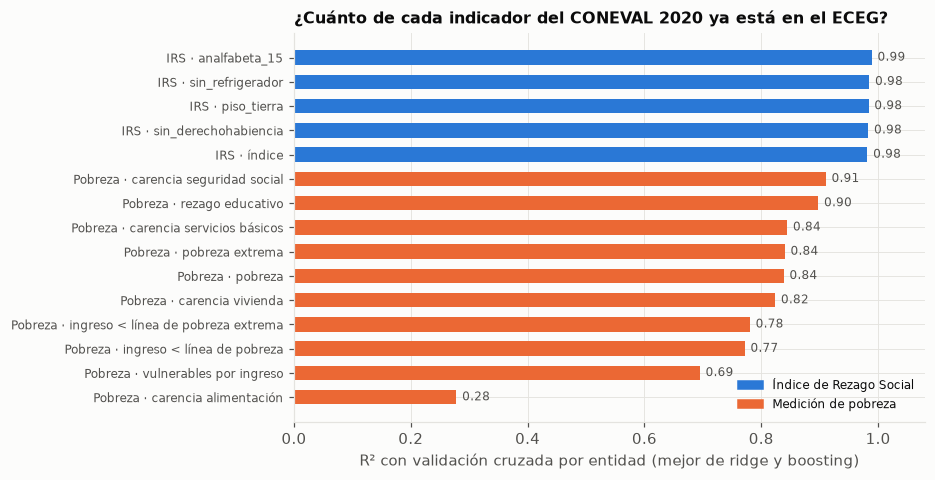

,R² ridge,R² boosting,R² (mejor)
objetivo,,,
IRS · analfabeta_15,0.99,0.98,0.99
IRS · sin_refrigerador,0.98,0.98,0.98
IRS · piso_tierra,0.98,0.97,0.98
IRS · sin_derechohabiencia,0.98,0.98,0.98
IRS · índice,0.98,0.96,0.98
Pobreza · carencia seguridad social,0.91,0.89,0.91
Pobreza · rezago educativo,0.89,0.90,0.90
Pobreza · carencia servicios básicos,0.80,0.84,0.84
Pobreza · pobreza extrema,0.84,0.84,0.84


In [37]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

objetivos = {"IRS · índice": ("irs", irs)}
objetivos.update({f"IRS · {c}": (c, irs) for c in ["analfabeta_15", "sin_derechohabiencia", "piso_tierra", "sin_refrigerador"]})
objetivos.update({f"Pobreza · {et}": (c, pob) for c, et in {
    "pobreza": "pobreza", "pobreza_extrema": "pobreza extrema", "vulnerables_por_ingreso": "vulnerables por ingreso",
    "poblacion_con_ingreso_inferior_a_la_linea_de_pobreza_por_ingresos": "ingreso < línea de pobreza",
    "poblacion_con_ingreso_inferior_a_la_linea_de_pobreza_extrema_por_ingresos": "ingreso < línea de pobreza extrema",
    "carencia_por_acceso_a_la_seguridad_social": "carencia seguridad social", "carencia_por_acceso_a_la_alimentacion": "carencia alimentación",
    "carencia_por_acceso_a_los_servicios_basicos_en_la_vivienda": "carencia servicios básicos", "rezago_educativo": "rezago educativo",
    "carencia_por_calidad_y_espacios_de_la_vivienda": "carencia vivienda"}.items()})

t0 = time.time()
base = X.dropna(subset=["mun_inegi"]).drop_duplicates("mun_inegi").set_index("mun_inegi")
filas = []
for nombre, (v, df) in objetivos.items():
    yv = df[df.anio == 2020].drop_duplicates("mun_inegi").set_index("mun_inegi")[v]
    dd = base.join(yv.rename("y"), how="inner").dropna(subset=["y"])
    Xm, ym, grupos = dd.drop(columns="y"), dd.y.values, (dd.index // 1000).values
    fila = {"objetivo": nombre, "fuente": nombre.split(" · ")[0]}
    for et, modelo in [("ridge", make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13)))),
                       ("boosting", HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=0))]:
        pred = cross_val_predict(modelo, Xm, ym, groups=grupos, cv=GroupKFold(n_splits=8))
        fila[f"R² {et}"] = 1 - ((ym - pred) ** 2).sum() / ((ym - ym.mean()) ** 2).sum()
    fila["R² (mejor)"] = max(fila["R² ridge"], fila["R² boosting"])
    filas.append(fila)
c3 = pd.DataFrame(filas)
print(f"Validación cruzada terminada en {time.time() - t0:.0f} s")

dd = c3.sort_values("R² (mejor)")
fig, ax = plt.subplots(figsize=(7.4, 4.6))
ax.barh(dd.objetivo, dd["R² (mejor)"], color=[CAT[0] if f == "IRS" else CAT[1] for f in dd.fuente], height=0.6)
for i, v in enumerate(dd["R² (mejor)"]):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8, color=TEXTO_2)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=CAT[0], label="Índice de Rezago Social"), Patch(color=CAT[1], label="Medición de pobreza")], loc="lower right", fontsize=8)
ax.set_xlim(0, 1.08); ax.tick_params(axis="y", labelsize=8)
ax.set_xlabel("R² con validación cruzada por entidad (mejor de ridge y boosting)")
ax.set_title("¿Cuánto de cada indicador del CONEVAL 2020 ya está en el ECEG?")
plt.show()
c3.set_index("objetivo").drop(columns="fuente").sort_values("R² (mejor)", ascending=False)

**Cómo leerla.** Una barra cerca de 1 significa que el ECEG ya contiene ese indicador. Una barra más corta, que el CONEVAL aporta información propia.

**Qué nos dice:**
- **El IRS es redundante** (R² = 0.98): se construye con variables del censo, las mismas del ECEG.
- **La pobreza aporta información nueva**, sobre todo en los indicadores de **ingreso** (0.69–0.78), que el censo por sección no mide.

Además, las dos fuentes están muy relacionadas entre sí:

In [38]:
ambas = irs[irs.anio == 2020].set_index("mun_inegi")[["irs"]].join(pob[pob.anio == 2020].set_index("mun_inegi")[["pobreza", "pobreza_extrema"]], how="inner")
ambas.corr().loc[["irs"], ["pobreza", "pobreza_extrema"]]

,pobreza,pobreza_extrema
irs,0.78,0.88


### 5.6 Decisión

| Criterio | IRS | Pobreza |
|---|---|---|
| C1 Cobertura | ✔ | ✔ |
| C2 Comparable en el tiempo | ✘ | ✔ |
| C3 Valor añadido sobre el ECEG | ✘ (R² 0.98) | ✔ (ingreso, R² 0.69–0.78) |
| C4 Granularidad | También por localidad | Municipal (y localidades urbanas en 2020) |
| C5 Interpretable en reglas | Índice compuesto | Porcentajes concretos |

**Se usa la medición de pobreza.** Hay una advertencia: las cifras municipales de pobreza son estimaciones de modelos, con su propio error, y parte de lo que el ECEG «no explica» puede ser ese error. Conviene usar pocos indicadores: ingreso inferior a la línea de pobreza y pobreza extrema.

---
## 6. Qué debe decidir la fase 3

| # | Decisión | Evidencia en este notebook |
|---|---|---|
| 1 | Universo: secciones con las seis elecciones o con al menos cinco | §3.5 |
| 2 | Qué hacer con las elecciones sin dato: 7,156 secciones con alguna elección con 100% de NS, más el hueco de 2012 | §3.3, §3.5, §4.5 |
| 3 | **Separar nivel y forma** antes de agrupar, porque el nivel es el 67% de la varianza | §4.5 |
| 4 | Umbral mínimo de lista nominal (200–300) o encogimiento hacia la media | §3.6 |
| 5 | Bandas de edad: excluir a los mayores de 100 años y revisar el salto de los 30–33 años | §3.4, §4.3 |
| 6 | No comparar distritos entre 2024 y los años anteriores | §2.1 |
| 7 | Contexto: ECEG por sección, pobreza municipal 2020 (con el cruce INE-INEGI) y, como candidata, la concurrencia con elecciones locales | §4.6, §5 |

**Estado de las hipótesis tras la fase 2:**
- **H2, solo presidenciales:** falla en la prueba preliminar (r = 0.16).
- **H3, jóvenes ausentes:** pasa (r = 0.55).
- **H5, en deterioro:** debe medirse descontando la regresión a la media.
- **H1 y H4** (constantes y abstención crónica) se evalúan en el modelado.